# Simulating the X-ray luminosity function (XLF) of an X-ray binary (XRB) population

In the previous labs, you explored populations of double compact object mergers, supernovae, and gamma-ray bursts. These phenomena are instantaneous transient events: they occur on timescales much shorter than the typical lifetime of a binary system. Within the POSYDON framework, such events can be modeled efficiently using an initial–final interpolation scheme, which maps the initial binary properties directly to their final, post-event outcome.

X-ray binaries, however, are fundamentally different. They represent evolutionary phases of binary systems that persist for a non-negligible fraction of the system’s lifetime. During these phases, the properties of the binaries—such as component masses, orbital periods, and X-ray luminosities—evolve continuously with time. Because of this temporal evolution, an initial–final interpolation approach is not sufficient to capture their behavior.

### Modeling strategies for X-ray binary populations

There are two principal approaches to model populations of systems like X-ray binaries:
1.  Snapshot method
-   Evolve each binary up to a pre-specified age.
-   Record its properties at that moment.
-   If the binary is in an X-ray phase at that time, include it in the population statistics.

2.	Full evolutionary history method
-   Evolve each binary from zero-age to the end of its life.
-   Identify all intervals during which the system qualifies as an X-ray binary.
-   Record the evolving properties of the system across these intervals, weighting them by the time spent in each state.

The "snapshot" method is conceptually straightforward but computationally inefficient: a binary may have been an X-ray source at earlier or later times, and its observable properties evolve during the X-ray phase, which is not fully captured by a single snapshot. This "full evolutionary history" method is more computationally efficient and captures the temporal evolution of the population in greater detail. It is however conceptualy more complex to implement.

![XRB schematic](xrb_schematic.png)
<details>
<summary>Code to produce this diagram</summary>

~~~python

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3))

# Timeline
ax.hlines(1, 0, 11, color="black")
ax.set_ylim(0.5, 1.6)
ax.set_xlim(0, 11)

# Key events
events = [0, 2, 8, 10]
labels = ["ZAMS", "1st Supernova", "2nd Supernova", "DCO formation"]
colors = ["black", "red", "red", "orange"]

for x, label, c in zip(events, labels, colors):
    ax.plot(x, 1, "o", color=c)
    ax.text(x, 1.12, label, ha="center", color=c, fontsize=10)

# X-ray binary phase between the two SNe
ax.hlines(0.9, 3, 7, color="blue", linewidth=6, alpha=0.3)
ax.text(5, 0.72, "X-ray Binary Phase", ha="center", color="blue")

# Snapshot method arrow (single age cut)
ax.annotate("Snapshot method\n(one age)", xy=(6, 1.05), xytext=(6, 1.38),
            arrowprops=dict(arrowstyle="->", color="darkgreen"),
            ha="center", color="darkgreen", fontsize=9)

# Full history method bracket
ax.annotate("", xy=(3, 1.28), xytext=(7, 1.28),
            arrowprops=dict(arrowstyle="|-|", color="purple", linewidth=2))
ax.text(5, 1.35, "Full history method", ha="center", color="purple", fontsize=9)

# Formatting
ax.axis("off")
ax.set_title("From ZAMS to Double Compact Object Formation", fontsize=14)

plt.savefig("xrb_schematic.png", dpi=150, bbox_inches="tight")

plt.show()

~~~

</details>



In this first lab, we will adopt the snapshot method: evolving binaries to a fixed age and recording their properties if they are X-ray binaries at that time. This will introduce the concepts and workflow for simulating X-ray binary populations. In the following lab, we will implement the full evolutionary history method, which provides a more complete and efficient treatment of these systems.



**By the end of this exercise, you should be able to:**
-   Set up and run a POSYDON population synthesis calculation appropriate for the modelling of high-mass X-ray binaries.
-   Load and inspect simulated populations, extracting key information such as the number of systems, simulated stellar mass, and their formation pathways.
-   Identify and select X-ray binaries within the broader population at a fixed age, using criteria based on stellar states and accretion properties.
-   Compute and analyze the X-ray luminosity function (XLF) by combining the luminosities of the simulated XRBs into a population distribution.
-   Visualize and interpret the results, linking simulation outputs to astrophysical observables, and discussing how population synthesis can be used to test models of binary evolution against X-ray observations of galaxies.



## 1.   Setting up the population run

First, let's load some required packages.


In [1]:
import os
print(os.getenv("PATH_TO_POSYDON"))
print(os.getenv("PATH_TO_POSYDON_DATA"))

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages
/srv/astro/projects/posydon/data_sync_staging/POSYDON_datasets/latest_stable/


In [1]:
#import posydon
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from posydon.config import PATH_TO_POSYDON, PATH_TO_POSYDON_DATA

## 1. First example

then, copy default population parameters file to current directory



In [2]:
path_to_params = os.path.join(PATH_TO_POSYDON, "posydon/popsyn/population_params_default.ini")
shutil.copyfile(path_to_params, './population_params_XLF.ini')

'./population_params_XLF.ini'

We need to open the population_params.ini file that we just copied and edit it adjust the parameters we need for our simulations. As in the previous lab, we will explore high-mass X-ray binaries, in star-forming galaxies. Often, star-formation rates in galaxies are measured assuming a constant star-formation rate over the last 100Myr. This is excactly what we will assume here as well. What are the changes that we would need to make in population_params.ini file?

<details>
<summary>Click to reveal code</summary>

~~~python
star_formation = 'constant'
# 'constant', 'burst', 'custom_linear', 'custom_log10',
# 'custom_linear_histogram', 'custom_log10_histogram'
max_simulation_time = 1e8
# float (0, inf)
~~~

</details>

Let's also define that we want to run 100 binaries at two different metallicities, Solar and 10% Solar.

<details>
<summary>Click to reveal code</summary>

~~~python
  number_of_binaries = 100
    # int (0, inf)
  metallicity = [1., 0.1]
    # in units of solar metallicity: list of float
    # e.g. [2., 1., 0.45, 0.2, 0.1, 0.01, 0.001, 0.0001]
~~~

</details>

Now it is time to run our test population. We will use as before the `PopulationRunner` class to set up the run, by reading the parameters from the file we just copied and edited to our current directory, and then run it with the `evolve` method. This might take a few minutes...


In [1]:
from posydon.popsyn.synthetic_population import PopulationRunner
poprun = PopulationRunner('./population_params_XLF.ini', verbose=True)
poprun.evolve()

100%|██████████| 1000/1000 [15:29<00:00,  1.08it/s]


Merging 1 files...
Files merged!
Saved merged files to 1e+00_Zsun_population.h5...
Removing files in /home/users/a/aguetar1/Posydon_Data/XLF_lab/1e+00_Zsun_batches...


100%|██████████| 1000/1000 [15:24<00:00,  1.08it/s]


Merging 34 files...
Files merged!
Saved merged files to 1e-01_Zsun_population.h5...
Removing files in /home/users/a/aguetar1/Posydon_Data/XLF_lab/1e-01_Zsun_batches...


We can also do it in another way by using a slurm job in order to run the simualtions on cluster. 
For example, to simulate 10000 binaries for $1 Z_{\odot}$ and $0.1 Z_{\odot}$ each, it is better to use the following command.

<details>
<summary> Command to send jobs </summary>

===================================================================================
~~~ python 

posydon-popsyn setup population_params_XLF.ini --job_array=10 \
                                            --walltime= X-xx:xx:xx \
                                            --mem_per_cpu=10G  \
                                            --partition=private-astro-cpu \
                                            --email=arnaud.aguet@etu.unige.ch \
                                            --account=fragkos

~~~
===================================================================================
</details>

We now need to load back the file of the population we run. Let's load the Solar metalicity population using the `Population` class.


In [3]:
from posydon.popsyn.synthetic_population import Population
pop = Population('../XLF_lab_Data/1e+00_Zsun_population.h5')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


There, we can check for things like the simulated mass, the number of systems, or look in a bit more detail as specific binary.


In [ ]:
print("Shows all the simulated metallicities as well as the total simulated mass per metallicities :")
display(pop.mass_per_metallicity)

# You can also access the total number of systems in the file with
display(f"The number of simulated binary systems are : {pop.number_of_systems}")

# Select only binary_index 5
print("History of the binary system 6 (index 5) throughout time :")
display(pop.history[5])

# Check the history lengths of binaries
print("\nIt shows how many steps the binary (given by the index) have been through :")
display(pop.history_lengths)

# Calculate and inspect the different formation channels
pop.calculate_formation_channels(mt_history=True)
# The formation channels are loaded in with pop.formation_channels
pop.formation_channels

Shows all the simulated metallicities as weel as the total simulated mass per metallicities.


,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
1.0,27421.825569,0.0,27421.825569,1000


'The number of simulated binary systems are : 1000'

History of the binary system 6 (index 5) throughout time :


,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
5,detached,ZAMS,6.581983e+06,1.500559,0.0,NaN,initial_cond,0.000000,H-rich_Core_H_burning,30.365261,...,NaN,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
5,contact,oCE2,8.842962e+06,0.992632,0.0,-2.539393,step_HMS_HMS,0.066372,H-rich_Core_H_burning,28.751009,...,0.000000,0.0,0.000000,0.000000,0.704929,2.806860e-01,7.145093e-01,0.271215,9.892662e-01,1.235668e+01
5,merged,oMerging2,8.842962e+06,0.992632,0.0,-2.539393,step_CE,0.000037,H-rich_Core_H_burning,28.751009,...,0.000000,0.0,0.000000,0.000000,0.704929,2.806860e-01,7.145093e-01,0.271215,9.892662e-01,1.235668e+01
5,merged,CC2,1.427721e+07,NaN,NaN,NaN,step_merged,2.757970,massless_remnant,0.000000,...,13.778488,NaN,12.804853,0.146945,0.000000,8.282724e-13,9.674508e-100,0.986155,2.761574e-15,9.053848e-15
5,merged,NaN,1.427721e+07,NaN,NaN,NaN,step_SN,0.020359,massless_remnant,0.000000,...,NaN,NaN,12.804853,NaN,NaN,NaN,NaN,NaN,NaN,9.711911e-15
5,merged,END,1.427721e+07,NaN,NaN,NaN,step_end,0.000035,massless_remnant,0.000000,...,NaN,NaN,12.804853,NaN,NaN,NaN,NaN,NaN,NaN,9.711911e-15



It shows how many steps the binary (given by the index) have been through.


,length
index,
0,8
1,5
2,5
3,5
4,6
...,...
995,6
996,6
997,8


Formation channels already exist in the parsed population file!
Channels will be overwriten


,channel_debug,channel
0,ZAMS_oRLO1_CC1_oRLO2_CC2_maxtime_END,ZAMS_oRLO1_CC1_oRLO2_CC2_maxtime_END
1,ZAMS_oRLO1_CC1_maxtime_END,ZAMS_oRLO1_CC1_maxtime_END
2,ZAMS_oRLO1_CC1_maxtime_END,ZAMS_oRLO1_CC1_maxtime_END
3,ZAMS_oCE1_FAILED_FAILED,ZAMS_oCE1_FAILED_FAILED
4,ZAMS_oRLO1_CC1_CC2_END,ZAMS_oRLO1_CC1_CC2_END
...,...,...
995,ZAMS_oRLO1_CC1_CC2_END,ZAMS_oRLO1_CC1_CC2_END
996,ZAMS_oRLO1_CC1_CC2_END,ZAMS_oRLO1_CC1_CC2_END
997,ZAMS_oRLO1_CC1_oRLO2_oCE2_oMerging2_END,ZAMS_oRLO1_CC1_oRLO2_oCE2_oMerging2_END
998,ZAMS_maxtime_END,ZAMS_maxtime_END


Unfortunately, with a 100 binary population, we cannot do much. To get a better feeling of what the population synthesis can do, we will use a pre-calculated population with 100K binaries at Z=0.0142 (solar metallicity). The file is called `1e+00_Zsun_population.h5` and it is located in the `data` folder of posydon. You can load it directly from there using the `Population` class.

In [2]:

from posydon.popsyn.synthetic_population import Population

file = './XRB_pop_runs_100K/1e+00_Zsun_population.h5'

pop = Population(file)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


### Excercise 1
Check the total number of binaries in this population, the simulated mass, how many unique formation pathways the binaries of this population have followed, and how many binaries have gone through each channel. 

Since in this lab, we only care about the properties of the binary at the end of our simulations, i.e. at 100Myr, we do not need to deal in most cases with the `history` but we can look at the `online` instead, which contains the initial and final properties of the binary. Thus, it would be handy to print a list of all the `keys` of `oneline`.

In [3]:
# Write here your code for Excercise 1

# Total number of systems per metallicity, the simulated mass
display("The total simulated mass and the number of systems are :", pop.mass_per_metallicity) 

# Show how many binaries there are per channels. The length given at the end gives the number of DIFFERENT channels
pop.calculate_formation_channels(mt_history = True)
display(f"All the different channels with the number of systems are :", pop.formation_channels.value_counts())

# Shows all the keys of the oneline function
print("Here is the whole list of keys of the function 'oneline()' :")
display(", ".join(list(pop.oneline[0].keys())))


'The total simulated mass and the number of systems are :'

,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
1.0,2.144936e+06,0.0,2.144936e+06,100000


Formation channels already exist in the parsed population file!
Channels will be overwriten


'All the different channels with the number of systems are :'

channel_debug                  channel                      
ZAMS_maxtime_END               ZAMS_maxtime_END                 23933
ZAMS_oRLO1_maxtime_END         ZAMS_oRLO1_maxtime_END           17911
ZAMS_oCE1_oMerging1_CC1_END    ZAMS_oCE1_oMerging1_CC1_END      15387
ZAMS_oRLO1_CC1_CC2_END         ZAMS_oRLO1_CC1_CC2_END            8544
ZAMS_oRLO1_CC1_maxtime_END     ZAMS_oRLO1_CC1_maxtime_END        8327
                                                                ...  
ZAMS_oDoubleCE1_FAILED         ZAMS_oDoubleCE1_FAILED               1
ZAMS_oDoubleCE2_maxtime_END    ZAMS_oDoubleCE2_maxtime_END          1
ZAMS_maxtime_FAILED            ZAMS_maxtime_FAILED                  1
ZAMS_oDoubleCE1_oRLO1_CC1_END  ZAMS_oDoubleCE1_oRLO1_CC1_END        1
ZAMS_oDoubleCE1_oRLO2_CC2_END  ZAMS_oDoubleCE1_oRLO2_CC2_END        1
Name: count, Length: 93, dtype: int64

Here is the whole list of keys of the function 'oneline()' :


'state_i, event_i, time_i, orbital_period_i, eccentricity_i, lg_mtransfer_rate_i, step_names_i, step_times_i, S1_state_i, S1_mass_i, S1_log_R_i, S1_log_L_i, S1_lg_mdot_i, S1_he_core_mass_i, S1_he_core_radius_i, S1_co_core_mass_i, S1_co_core_radius_i, S1_center_h1_i, S1_center_he4_i, S1_surface_h1_i, S1_surface_he4_i, S1_surf_avg_omega_div_omega_crit_i, S1_spin_i, S2_state_i, S2_mass_i, S2_log_R_i, S2_log_L_i, S2_lg_mdot_i, S2_he_core_mass_i, S2_he_core_radius_i, S2_co_core_mass_i, S2_co_core_radius_i, S2_center_h1_i, S2_center_he4_i, S2_surface_h1_i, S2_surface_he4_i, S2_surf_avg_omega_div_omega_crit_i, S2_spin_i, state_f, event_f, time_f, orbital_period_f, eccentricity_f, lg_mtransfer_rate_f, step_names_f, step_times_f, S1_state_f, S1_mass_f, S1_log_R_f, S1_log_L_f, S1_lg_mdot_f, S1_he_core_mass_f, S1_he_core_radius_f, S1_co_core_mass_f, S1_co_core_radius_f, S1_center_h1_f, S1_center_he4_f, S1_surface_h1_f, S1_surface_he4_f, S1_surf_avg_omega_div_omega_crit_f, S1_spin_f, S2_state_f, S

<details>
<summary>Solution of excercise 1</summary>

~~~python
print("The simulated mass  and numbe of binaries per metallicity is:")
print(pop.mass_per_metallicity)
print('')

# Calculate and inspect the different formation channels
pop.calculate_formation_channels(mt_history=True)
print('')

# the formation channels are loaded in with pop.formation_channels.
print("The number of binaries following each formation channels are:")
print(pop.formation_channels.value_counts())
print('')

#The keys of oneline are:
print(", ".join(list(pop.oneline[0].keys())))
print('')
~~~

</details>

## 2.   Selecting the XRB population

Out of the entire population that we simulated, only a small fraction are potentially XRBs. So we do not need to be carrying everything around. To do that, we are gonna try to follow as closely as possible the tutorial on ["Transient populations"](https://posydon.org/POSYDON/latest/tutorials-examples/population-synthesis/bbh_analysis.html). You can consult that for inspiration. However, Since here we are dealing with XRBs and not transients, some of the steps will have to be adapted.


### Excercise 2
First, let's filter our populations to only select potential XRBs. For a binary to be and XRB, one of the two components must be a neutron star or a black hole, while the other must be a normal, non-compact star. Of course, some binaries get disrupted during the supernova. We need to get rid of those as well. The goal to save the indices of all binaries that may be XRBs into a list that we will name `selected_indices`.

<details>
<summary>Tips</summary>

From the states of compact object companions, apart from `NS` and `BH`  we also want to exclude the states `WD` and `massless remnant`.

Following the tutorial logic, we need to create a temporary dataframe from the `online` that includes the fields `S1_state_f`,  `S1_state_f`, and `state_f`. That way, it will be easier to buid a mask that implements our logic. 


</details>

In [6]:
pop.oneline.select(columns=['state_f', 'S1_spin_f', 'S2_spin_f', 'S1_state_f', 'S2_state_f', 'eccentricity_f'])

,state_f,S1_spin_f,S2_spin_f,S1_state_f,S2_state_f,eccentricity_f
binary_index,,,,,,
0,merged,0.000000,NaN,BH,massless_remnant,NaN
1,merged,0.081895,NaN,BH,massless_remnant,NaN
2,merged,0.000000,NaN,NS,massless_remnant,NaN
3,detached,0.852197,0.664924,H-rich_Core_H_burning,H-rich_Core_H_burning,0.0
4,ERR,0.540276,8.657208,stripped_He_Core_He_depleted,H-rich_Core_H_burning,0.0
...,...,...,...,...,...,...
99995,detached,0.022370,0.020330,H-rich_Core_H_burning,H-rich_Core_H_burning,0.0
99996,detached,2.641788,1.911766,H-rich_Core_H_burning,H-rich_Core_H_burning,0.0
99997,detached,0.003261,0.002832,H-rich_Core_H_burning,H-rich_Core_H_burning,0.0


In [4]:
# write your code for Excercise 2

tmp_data = pop.oneline.select(columns=['S1_state_f', 'S2_state_f','event']) # Final state of S1 and S2 and the list of events

S1_state = tmp_data['S1_state_f']
S2_state = tmp_data['S2_state_f']

indices = tmp_data.index

compact_object = {'BH', 'NS'}
compact_to_exclude = {'BH', 'NS', 'massless_remnant', 'WD'}

mask = (S1_state.isin(compact_object) & ~S2_state.isin(compact_to_exclude) | ~S1_state.isin(compact_to_exclude) & S2_state.isin(compact_object))

selected_indices = indices[mask].to_list()

display(f"The number of selected indices is of {len(selected_indices)} systems.")

display("Here are the states for both star at each selected indices :", pop.oneline.select(selected_indices, columns=['S1_state_f', 'S2_state_f']))


'The number of selected indices is of 8135 systems.'

'Here are the states for both star at each selected indices :'

,S1_state_f,S2_state_f
binary_index,,
29,NS,H-rich_Core_H_burning
54,NS,H-rich_Core_H_burning
56,NS,H-rich_Core_H_burning
82,NS,H-rich_Core_H_burning
104,NS,H-rich_Core_H_burning
...,...,...
99936,NS,H-rich_Core_He_burning
99941,NS,H-rich_Core_H_burning
99946,NS,H-rich_Core_H_burning


<details>
<summary>Solution of excercise 1</summary>

~~~python

tmp_data = pop.oneline.select(columns=['S1_state_f', 'S2_state_f'])
S1_state = tmp_data['S1_state_f']
S2_state = tmp_data['S2_state_f']

# get the indices of all systems
indices = tmp_data.index

compact = {'BH', 'NS'}
exclude = {'BH', 'NS', 'massless_remnant', 'WD'}

mask = (S1_state.isin(compact) & ~S2_state.isin(exclude)) | (S2_state.isin(compact) & ~S1_state.isin(exclude))

# get the indices that satisfy all the conditions
selected_indices = indices[mask].to_list()

print(selected_indices)
pop.oneline[selected_indices]

~~~

</details>

Before we continue, let's save this filtered population into a new file (e.g. `XRBs.h5`), and then reload it into a new population that we will call `XRB_pop`.


In [5]:
# set overwrite to False to add to the file
pop.export_selection(selected_indices, '../XLF_lab_Data/XRBs.h5', append=False, overwrite=True)

XRB_pop = Population('../XLF_lab_Data/XRBs.h5')
display(f"The number of systems is : {XRB_pop.number_of_systems}")

#Note that the simulated mass is the same as what was reported before the filtering. This information is retained.
display(XRB_pop.mass_per_metallicity)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


'The number of systems is : 8135'

,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
1.0,2.144936e+06,0.0,2.144936e+06,8135


The next step in the ["Transient populations"](https://posydon.org/POSYDON/latest/tutorials-examples/population-synthesis/bbh_analysis.html) tutorial is to build a selection function. There, we basically need to constract a pandas dataframe which contains only the information that we need for our further analysis. We will build this step by step, as in the tutorial.

For the later calculations we are gonna do, it is convenient to switch from an S1 / S2 notation to donnor / accretor notation. To do that, we will need in the selection funtion to loop over the systems and check which one is the compact object (BH or NS) and assign that to be the accretor, while the other star will be the donor. in contrast to the the tutorial for "transients" where we want to be searching the history, here we only care about the final state, so the oneline is sufficient.



In [7]:
def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk=None):
    '''A XRB selection function to create a population of XRBs, where we store only the necessary information.'''

    indices = oneline_chunk.index.to_numpy()
    df_XRBs = pd.DataFrame(index = indices)


    df_XRBs['Time'] = oneline_chunk['time_f'] * 1e-6 #Myr
    df_XRBs['Metallicity'] = oneline_chunk['metallicity'] #This is not really necessary in our case, since we have one file per metallicity, but it is required by the fonctionality of the "transient population we will use"

  
    # Compact object types
    compact_types = {'BH', 'NS'}

    # Prepare new columns
    donor_mass = []
    accretor_mass = []
    donor_type = []
    accretor_type = []


    # Loop over each system
    for s1, s2, m1, m2 in zip(oneline_chunk['S1_state_f'], oneline_chunk['S2_state_f'], oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f']):
        if s1 in compact_types and s2 not in compact_types:
            accretor_mass.append(m1)
            accretor_type.append(s1)
            donor_mass.append(m2)
            donor_type.append(s2)

        elif s2 in compact_types and s1 not in compact_types:
            accretor_mass.append(m2)
            accretor_type.append(s2)
            donor_mass.append(m1)
            donor_type.append(s1)

        else:
            # If neither or both are compact, fill with NaN or original values
            accretor_mass.append(float('nan'))
            accretor_type.append(None)
            donor_mass.append(float('nan'))
            donor_type.append(None)

    # Add new columns to DataFrame
    df_XRBs['Donor_mass'] = donor_mass
    df_XRBs['Accretor_mass'] = accretor_mass
    df_XRBs['Donor_type'] = donor_type
    df_XRBs['Accretor_type'] = accretor_type

    return df_XRBs

Let's test our function to one binary.


In [8]:
# We test the function on the binary system 1 with index 0. 
idx = np.arange(20)
XRB_selection_function(XRB_pop.history[idx], XRB_pop.oneline[idx], None)

,Time,Metallicity,Donor_mass,Accretor_mass,Donor_type,Accretor_type
0,100.0,1.0,7.376104,1.277584,H-rich_Core_H_burning,NS
1,100.0,1.0,5.918592,1.277584,H-rich_Core_H_burning,NS
2,100.0,1.0,7.072865,1.277584,H-rich_Core_H_burning,NS
3,100.0,1.0,3.891464,1.278972,H-rich_Core_H_burning,NS
4,100.0,1.0,5.938589,1.287201,H-rich_Core_H_burning,NS
5,100.0,1.0,5.624684,1.286173,H-rich_Core_H_burning,NS
6,100.0,1.0,4.594987,1.302877,H-rich_Core_H_burning,NS
7,100.0,1.0,3.807135,1.253122,H-rich_Core_H_burning,NS
8,100.0,1.0,3.762380,1.302021,H-rich_Core_H_burning,NS
9,100.0,1.0,5.105047,1.277584,H-rich_Core_H_burning,NS


### Excercise 3

Now let's modify `XRB_selection_function` that we built above, to also include additional information, such as donor and accretor radii, mass loss/transfer rates, orbital period, and eccentricity, as well as the rotational frequency of the donor and the spin of the accreting compact object.

<details>
<summary>Tip</summary>

In POSYDON, we keep track of the mass loss/gain rate of each component, as well the mass transfer rate between the two components. The latter is non-zero only for Roche lobe overfilling systems. Let'. save all three quantities, i.e.: `S1_lg_mdot_f`, `S2_lg_mdot_f`, and `lg_mtransfer_rate_f`.

</details>

In [19]:
import math

keys = list(XRB_pop.oneline[0].keys())
n_cols = 4  # ou 3 si tu veux moins large

# Calcul du nombre de lignes nécessaires
n_rows = math.ceil(len(keys) / n_cols)

# Répartition équilibrée en colonnes
cols = [keys[i::n_rows] for i in range(n_rows)]

# Trouver la largeur maximale de chaque colonne pour alignement propre
col_widths = []
for j in range(n_cols):
    col_items = [keys[i + j * n_rows] for i in range(n_rows) if i + j * n_rows < len(keys)]
    max_len = max(len(k) for k in col_items)
    col_widths.append(max_len)

with open("Oneline_keys.txt", "w", encoding="utf-8") as f:
    for i in range(n_rows):
        row_items = []
        for j in range(n_cols):
            idx = i + j * n_rows
            if idx < len(keys):
                # Aligner à gauche avec largeur fixe
                row_items.append(keys[idx].ljust(col_widths[j] + 3))
        f.write("".join(row_items).rstrip() + "\n")


with open("Oneline_keys.txt", "r", encoding="utf-8") as f:
    print(f.read())

state_i                              S2_log_L_i                           S1_he_core_radius_f                  S1_natal_kick_array_2
event_i                              S2_lg_mdot_i                         S1_co_core_mass_f                    S1_natal_kick_array_3
time_i                               S2_he_core_mass_i                    S1_co_core_radius_f                  S1_SN_type
orbital_period_i                     S2_he_core_radius_i                  S1_center_h1_f                       S1_f_fb
eccentricity_i                       S2_co_core_mass_i                    S1_center_he4_f                      S1_spin_orbit_tilt_first_SN
lg_mtransfer_rate_i                  S2_co_core_radius_i                  S1_surface_h1_f                      S1_spin_orbit_tilt_second_SN
step_names_i                         S2_center_h1_i                       S1_surface_he4_f                     S2_natal_kick_array_0
step_times_i                         S2_center_he4_i                      S1_surf

In [8]:
# Write here your code for Excercise 3

def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk=None):
    '''A XRB selection function to create a population of XRBs, where we store only the necessary information.'''

    indices = oneline_chunk.index.to_numpy()
    df_XRBs = pd.DataFrame(index = indices)


    df_XRBs['Time'] = oneline_chunk['time_f'] * 1e-6 #Myr
    df_XRBs['Metallicity'] = oneline_chunk['metallicity'] #This is not really necessary in our case, since we have one file per metallicity, but it is required by the fonctionality of the "transient population we will use"

  
    # Compact object types
    compact_types = {'BH', 'NS'}

    # Prepare new columns
    donor_mass = []
    donor_type = []
    donor_lg_mdot =[]
    donor_log_radius = []
    donor_surf_avg_omega_div_omega_crit = []

    accretor_mass = []
    accretor_type = []
    accretor_lg_mdot = []
    accretor_log_radius = []
    accretor_spin = []

    # Loop over each system
    for s1, s2, m1, m2, mdot1, mdot2, spin1, spin2, logr1, logr2, Om1, Om2 in zip(oneline_chunk['S1_state_f'], oneline_chunk['S2_state_f'], 
                                                       oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'], 
                                                       oneline_chunk['S1_lg_mdot_f'],oneline_chunk['S2_lg_mdot_f'], 
                                                       oneline_chunk['S1_spin_f'], oneline_chunk['S2_spin_f'],
                                                       oneline_chunk['S1_log_R_f'], oneline_chunk['S2_log_R_f'],
                                                       oneline_chunk['S1_surf_avg_omega_div_omega_crit_f'], 
                                                       oneline_chunk['S2_surf_avg_omega_div_omega_crit_f']):

        if s1 in compact_types and s2 not in compact_types:

            accretor_mass.append(m1)
            accretor_type.append(s1)
            accretor_lg_mdot.append(mdot1)
            accretor_spin.append(spin1)
            accretor_log_radius.append(logr1)

            donor_mass.append(m2)
            donor_type.append(s2)
            donor_lg_mdot.append(mdot2)
            donor_log_radius.append(logr2)
            donor_surf_avg_omega_div_omega_crit.append(Om2)
            

        elif s2 in compact_types and s1 not in compact_types:

            accretor_mass.append(m2)
            accretor_type.append(s2)
            accretor_lg_mdot.append(mdot2)
            accretor_spin.append(spin2)
            accretor_log_radius.append(logr2)

            donor_mass.append(m1)
            donor_type.append(s1)
            donor_lg_mdot.append(mdot1)
            donor_log_radius.append(logr1)
            donor_surf_avg_omega_div_omega_crit.append(Om1)

        else:
            # If neither or both are compact, fill with NaN or original values
            accretor_mass.append(float('NaN'))
            accretor_type.append(None)
            donor_mass.append(float('NaN'))
            donor_type.append(None)
            accretor_lg_mdot.append(float('NaN'))
            donor_lg_mdot.append(float('NaN'))
            accretor_spin.append(float('NaN'))
            accretor_log_radius.append(float('NaN'))
            donor_log_radius.append(float('NaN'))

    # Add new columns to DataFrame
    df_XRBs['Donor_mass'] = donor_mass
    df_XRBs['Accretor_mass'] = accretor_mass
    df_XRBs['Donor_log_radius'] = donor_log_radius
    df_XRBs['Accretor_log_radius'] = accretor_log_radius
    df_XRBs['Donor_type'] = donor_type
    df_XRBs['Accretor_type'] = accretor_type
    df_XRBs['Accretor_spin'] = accretor_spin
    df_XRBs['Accretor_lg_mdot'] = accretor_lg_mdot
    df_XRBs['Donor_lg_mdot'] = donor_lg_mdot
    df_XRBs['Rotational_freq_donor'] = donor_surf_avg_omega_div_omega_crit
    
    df_XRBs['Orbital_period'] = oneline_chunk['orbital_period_f'].to_numpy()
    df_XRBs['Eccentricity'] = oneline_chunk['eccentricity_f']
    df_XRBs['Log_mass_transfer_rate'] = oneline_chunk['lg_mtransfer_rate_f']

    return df_XRBs


<details>
<summary> Solution of Excercise 3</summary>

~~~python

import pandas as pd
def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk=None):
    '''A XRB selection function to create a population of XRBs, where we store only the necessary information.'''

    indices = oneline_chunk.index.to_numpy()
    df_XRBs = pd.DataFrame(index = indices)

    #in contrast to the the tutorial for "transient" where we want to be searching the history, here we only care about the final state, so the oneline is sufficient.

    df_XRBs['time'] = oneline_chunk['time_f'] * 1e-6 #Myr
    df_XRBs['time_of_birth'] = oneline_chunk['time_i'] * 1e-6 #Myr
    df_XRBs['metallicity'] = oneline_chunk['metallicity'] #This is not really necessary in our case, since we have one file per metallicity, but it is required by the fanctionality of the "transient population we will use"

    # For the later calculations we are gonna do, it is convenient to switch from an S1 / S2 notation to donnor / accretor notation. 
    # To do that, we will loop over the systems and check which one is the compact object (BH or NS) and assign that to be the accretor, while the other star will be the donor.
    # We will also store the type of compact object in a separate column.
  
    # Compact object types
    compact_types = {'BH', 'NS'}

    # Prepare new columns
    donor_mass = []
    accretor_mass = []
    donor_state = []
    accretor_state = []
    donor_log_R = []
    accretor_log_R = []
    donor_lg_mdot = [] 
    accretor_lg_mdot = []
    donor_surf_avg_omega_div_omega_crit = []
    accretor_spin = []



    # Loop over each system
    for s1, s2, m1, m2, logr1, logr2, mdot1, mdot2, omega1, omega2, spin1, spin2 in zip(oneline_chunk['S1_state_f'], oneline_chunk['S2_state_f'], oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'], oneline_chunk['S1_log_R_f'], oneline_chunk['S2_log_R_f'], oneline_chunk['S1_lg_mdot_f'], oneline_chunk['S2_lg_mdot_f'], oneline_chunk['S1_surf_avg_omega_div_omega_crit_f'], oneline_chunk['S2_surf_avg_omega_div_omega_crit_f'], oneline_chunk['S1_spin_f'], oneline_chunk['S2_spin_f']):
        if s1 in compact_types and s2 not in compact_types:
            accretor_mass.append(m1)
            accretor_state.append(s1)
            accretor_log_R.append(logr1)
            accretor_lg_mdot.append(mdot1)
            accretor_spin.append(spin1)
            donor_mass.append(m2)
            donor_state.append(s2)
            donor_log_R.append(logr2)   
            donor_lg_mdot.append(mdot2)
            donor_surf_avg_omega_div_omega_crit.append(omega2)
        elif s2 in compact_types and s1 not in compact_types:
            accretor_mass.append(m2)
            accretor_state.append(s2)
            accretor_log_R.append(logr2)
            accretor_lg_mdot.append(mdot2)
            accretor_spin.append(spin2)
            donor_mass.append(m1)
            donor_state.append(s1)
            donor_log_R.append(logr1)
            donor_lg_mdot.append(mdot1)
            donor_surf_avg_omega_div_omega_crit.append(omega1)
        else:
            # If neither or both are compact, fill with NaN or original values
            accretor_mass.append(float('nan'))
            accretor_state.append(None)
            accretor_log_R.append(float('nan'))
            accretor_lg_mdot.append(float('nan'))
            accretor_spin.append(float('nan'))
            donor_mass.append(float('nan'))
            donor_state.append(None)
            donor_log_R.append(float('nan'))
            donor_lg_mdot.append(float('nan'))
            donor_surf_avg_omega_div_omega_crit.append(float('nan'))

    # Add new columns to DataFrame
    df_XRBs['donor_mass'] = donor_mass
    df_XRBs['accretor_mass'] = accretor_mass
    df_XRBs['donor_state'] = donor_state
    df_XRBs['accretor_state'] = accretor_state
    df_XRBs['donor_log_R'] = donor_log_R
    df_XRBs['accretor_log_R'] = accretor_log_R
    df_XRBs['donor_lg_mdot'] = donor_lg_mdot
    df_XRBs['accretor_lg_mdot'] = accretor_lg_mdot
    df_XRBs['donor_surf_avg_omega_div_omega_crit'] = donor_surf_avg_omega_div_omega_crit
    df_XRBs['accretor_spin'] = accretor_spin

    # Finaly, add columns that are not associated to teh donor or the accretor
    df_XRBs['orbital_period'] = oneline_chunk['orbital_period_f'].to_numpy()  # days
    df_XRBs['eccentricity'] = oneline_chunk['eccentricity_f'] 
    df_XRBs['lg_mtransfer_rate'] = oneline_chunk['lg_mtransfer_rate_f'] #Msun/yr


    return df_XRBs

~~~
</details>

We just have one more quantity to calculate, but it is an important one: the X-ray luminosity! Let's try to follow a simplified of the approach describe in Section 2.2. of [Misra et al. (2023)](https://ui.adsabs.harvard.edu/abs/2023A%26A...672A..99M/abstract), where we will neglect for now Be XRBs, as well as geometrical beaming effects of compact objects accreting at super-Eddington rates.

Let's write a function that takes as arguments the masses, radii, and types of the donor and the accretor, as well as the mass transfer rate between the donor and the accretor and the mass-loss rate of the donor star. The latter includes both wind mass loss and mass transfer due to RLO.


In [6]:
# Constants (cgs)
G = 6.67430e-8
Msun = 1.98847e33
Rsun = 6.957e10
c = 2.99792458e10
year = 3.15576e7

'''
np.clip(x, a, b) is a function that will set your input value at a if smaller than a and b if bigger than b. 
In between, the value stay unchanged. 
e.g. x = 1, np.clip(x,2,3) >>> 2, np.clip(x,0, 0.5) >>> 0.5, np.clip(x, 0, 2) >>> 1
     x = [1,2,3,4,5], np.clip(x,2,4) >>> [2, 2, 3, 4, 4]

np.isfinite() is a test function that returns a boolean (True/False). Check if the number is finite (i.e. not infinity nor NaN)
'''

def bh_efficiency_from_spin(a):
    if a is None or not np.isfinite(a):
        return 0.1
    a = float(np.clip(a, 0.0, 0.998))
    return 0.057 + 0.38 * a  # crude approx

# From 3rd Kepler's law
def separation_from_period(P_days, Mtot_Msun):
    P = float(P_days) * 86400.0
    Mtot = float(Mtot_Msun) * Msun
    return (G * Mtot * (P / (2.0 * np.pi))**2)**(1.0/3.0)  # cm

def guess_wind_speed(donor_mass_Msun, donor_radius_Rsun, scale=2.6):
    M = float(donor_mass_Msun) * Msun
    R = float(donor_radius_Rsun) * Rsun
    v_esc = np.sqrt(2 * G * M / max(R, 1e-10))
    return scale * v_esc  # cm/s

def bhl_mdot_acc(M_acc_Msun, Mdot_w_Msun_per_yr, a_cm, v_rel_cms, alpha_BHL=1.0):
    Macc = float(M_acc_Msun) * Msun
    Mdot_w = float(max(Mdot_w_Msun_per_yr, 0.0)) * Msun / year  # g/s
    vrel4 = max(v_rel_cms, 1.0)**4
    a2 = max(a_cm, 1.0)**2
    frac = alpha_BHL * (G**2 * Macc**2) / (a2 * vrel4)
    return frac * Mdot_w  # g/s

def _lg_msunyr_to_msunyr(lg_rate):
    if lg_rate is None or not np.isfinite(lg_rate):
        return 0.0
    return 10.0**float(lg_rate)

def compute_Lx_components(
    donor_mass, donor_log_R,
    accretor_mass, accretor_type,
    lg_mtransfer_rate, donor_lg_mdot, accretor_lg_mdot,
    orbital_period_days=None, accretor_spin=None):

    # Efficiency
    if accretor_type == 'NS':
        eta = 0.2
    elif accretor_type == 'BH':
        eta = bh_efficiency_from_spin(accretor_spin)
    else:
        return np.nan, np.nan, np.nan  # non-compact accretor

    # Rates in Msun/yr
    mdot_rlo_Msunyr = _lg_msunyr_to_msunyr(accretor_lg_mdot)          # RLO only
    mdot_wind_only_Msunyr = _lg_msunyr_to_msunyr(donor_lg_mdot) - _lg_msunyr_to_msunyr(lg_mtransfer_rate) # Mass loss through winds

 
    # mdot_rlo_Msunyr = _lg_msunyr_to_msunyr(lg_mtransfer_rate)          # RLO only
    # mdot_donor_total_Msunyr = _lg_msunyr_to_msunyr(donor_lg_mdot)       # winds + possible RLO
    # mdot_wind_only_Msunyr = max(mdot_donor_total_Msunyr - mdot_rlo_Msunyr, 0.0)

    # RLO luminosity (no Edd cap)
    mdot_rlo_gps = mdot_rlo_Msunyr * Msun / year # gps = gramm per second
    Lx_RLO = eta * mdot_rlo_gps * c**2 if mdot_rlo_Msunyr > 0.0 else 0.0

    # BHL luminosity (no Edd cap). If info missing, set to 0.
    Lx_BHL = 0.0

    a = separation_from_period(orbital_period_days, (donor_mass or 0.0) + (accretor_mass or 0.0))
    donor_Rsun = 10.0**donor_log_R
    v_w = guess_wind_speed(donor_mass, donor_Rsun)
    v_orb = 2.0 * np.pi * a / (float(orbital_period_days) * 86400.0)
    v_rel = np.sqrt(v_w**2 + v_orb**2)  # ignore eccentricity
    mdot_bhl_gps = bhl_mdot_acc(accretor_mass, mdot_wind_only_Msunyr, a, v_rel)
    if np.isfinite(mdot_bhl_gps) and mdot_bhl_gps > 0.0:
        Lx_BHL = eta * mdot_bhl_gps * c**2

    Lx_total = Lx_RLO + Lx_BHL
    return float(Lx_RLO), float(Lx_BHL), float(Lx_total)




def XRB_selection_function1(history_chunk, oneline_chunk, formation_channels_chunk=None):
    '''A XRB selection function to create a population of XRBs, where we store only the necessary information.'''

    indices = oneline_chunk.index.to_numpy()
    df_XRBs = pd.DataFrame(index = indices)

    #in contrast to the the tutorial for "transient" where we want to be searching the history, here we only care about the final state, so the oneline is sufficient.

    df_XRBs['time'] = oneline_chunk['time_f'] * 1e-6 #Myr
    df_XRBs['Time of birth'] = oneline_chunk['time_i'] * 1e-6 #Myr
    df_XRBs['metallicity'] = oneline_chunk['metallicity'] #This is not really necessary in our case, since we have one file per metallicity, but it is required by the fanctionality of the "transient population we will use"

    # For the later calculations we are gonna do, it is convenient to switch from an S1 / S2 notation to donnor / accretor notation. 
    # To do that, we will loop over the systems and check which one is the compact object (BH or NS) and assign that to be the accretor, while the other star will be the donor.
    # We will also store the type of compact object in a separate column.
  
    # Compact object types
    compact_types = {'BH', 'NS'}

    # Prepare new columns
    donor_mass = []
    accretor_mass = []
    donor_state = []
    accretor_state = []
    donor_log_R = []
    accretor_log_R = []
    donor_lg_mdot = [] 
    accretor_lg_mdot = []
    donor_surf_avg_omega_div_omega_crit = []
    accretor_spin = []

    Lx_rlo = []
    Lx_bhl = []
    Lx_tot = []

    # Loop over each system
    for s1, s2, m1, m2, logr1, logr2, mdot1, mdot2, omega1, omega2, spin1, spin2 in zip(oneline_chunk['S1_state_f'], oneline_chunk['S2_state_f'],
                                                                                        oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'],
                                                                                        oneline_chunk['S1_log_R_f'], oneline_chunk['S2_log_R_f'], 
                                                                                        oneline_chunk['S1_lg_mdot_f'], oneline_chunk['S2_lg_mdot_f'], 
                                                                                        oneline_chunk['S1_surf_avg_omega_div_omega_crit_f'], 
                                                                                        oneline_chunk['S2_surf_avg_omega_div_omega_crit_f'], 
                                                                                        oneline_chunk['S1_spin_f'], oneline_chunk['S2_spin_f']):
        
        if s1 in compact_types and s2 not in compact_types:
            accretor_mass.append(m1)
            accretor_state.append(s1)
            accretor_log_R.append(logr1)
            accretor_lg_mdot.append(mdot1)
            accretor_spin.append(spin1)

            donor_mass.append(m2)
            donor_state.append(s2)
            donor_log_R.append(logr2)   
            donor_lg_mdot.append(mdot2)
            donor_surf_avg_omega_div_omega_crit.append(omega2)

        elif s2 in compact_types and s1 not in compact_types:
            accretor_mass.append(m2)
            accretor_state.append(s2)
            accretor_log_R.append(logr2)
            accretor_lg_mdot.append(mdot2)
            accretor_spin.append(spin2)

            donor_mass.append(m1)
            donor_state.append(s1)
            donor_log_R.append(logr1)
            donor_lg_mdot.append(mdot1)
            donor_surf_avg_omega_div_omega_crit.append(omega1)

        else:
            # If neither or both are compact, fill with NaN or original values
            accretor_mass.append(float('nan'))
            accretor_state.append(None)
            accretor_log_R.append(float('nan'))
            accretor_lg_mdot.append(float('nan'))
            accretor_spin.append(float('nan'))

            donor_mass.append(float('nan'))
            donor_state.append(None)
            donor_log_R.append(float('nan'))
            donor_lg_mdot.append(float('nan'))
            donor_surf_avg_omega_div_omega_crit.append(float('nan'))

    # Add new columns to DataFrame
    df_XRBs['Donor mass'] = donor_mass
    df_XRBs['Accretor mass'] = accretor_mass
    df_XRBs['Donor state'] = donor_state
    df_XRBs['Accretor state'] = accretor_state
    df_XRBs['Donor log(R)'] = donor_log_R
    df_XRBs['Accretor log(R)'] = accretor_log_R
    df_XRBs['Donor log(mdot)'] = donor_lg_mdot
    df_XRBs['Accretor log(mdot)'] = accretor_lg_mdot
    df_XRBs['Donor surf_avg_omega_div_omega_crit'] = donor_surf_avg_omega_div_omega_crit
    df_XRBs['Accretor spin'] = accretor_spin

    # Finaly, add columns that are not associated to teh donor or the accretor
    df_XRBs['Orbital period'] = oneline_chunk['orbital_period_f'].to_numpy()  # days
    df_XRBs['Eccentricity'] = oneline_chunk['eccentricity_f'] 
    df_XRBs['Log(mtransfer_rate)'] = oneline_chunk['lg_mtransfer_rate_f'] #Msun/yr



    for _, r in df_XRBs.iterrows():
        Lx_RLO, Lx_BHL, Lx = compute_Lx_components(
            donor_mass=r.get('Donor mass'),
            donor_log_R=r.get('Donor log(R)'),
            accretor_mass=r.get('Accretor mass'),
            accretor_type=r.get('Accretor state'),
            lg_mtransfer_rate=r.get('Log(mtransfer_rate)'),    # log10(Msun/yr)
            donor_lg_mdot=r.get('Donor log(mdot)'),            # log10(Msun/yr), may include RLO
            accretor_lg_mdot=r.get('Accretor log(mdot)'),      # log10(Msun/yr), includes only RLO
            orbital_period_days=r.get('Orbital period'),
            accretor_spin=r.get('Accretor spin'))
        Lx_rlo.append(Lx_RLO)
        Lx_bhl.append(Lx_BHL)
        Lx_tot.append(Lx)
        
    df_XRBs['Lx_RLO'] = Lx_rlo
    df_XRBs['Lx_BHL'] = Lx_bhl
    df_XRBs['Lx_Tot'] = Lx_tot

    return df_XRBs


### Excercise 4
Let's try our new selection function which include the X-ray luminosity function first on just one binary, and then to the entire population.
 

In [22]:
select_infos = XRB_pop.oneline.select(columns=['S1_state_f', 'S2_state_f','event', 'orbital_period_f','lg_mtransfer_rate_f'])

In [19]:
# Write here your code for Excercise 4

display(XRB_selection_function1(XRB_pop.history[4504], XRB_pop.oneline[4504], formation_channels_chunk=None))
XRBs = XRB_pop.create_transient_population(XRB_selection_function1, 'XRB')

,time,Time of birth,metallicity,Donor mass,Accretor mass,Donor state,Accretor state,Donor log(R),Accretor log(R),Donor log(mdot),Accretor log(mdot),Donor surf_avg_omega_div_omega_crit,Accretor spin,Orbital period,Eccentricity,Log(mtransfer_rate),Lx_RLO,Lx_BHL,Lx_Tot
4504,100.0,31.81777,1.0,1.190958,1.198916,stripped_He_Core_He_depleted,NS,-0.202212,-4.745687,-5.517043,-7.427656,0.382704,0.008883,0.153139,0.0,-5.532719,4.230875e+38,9.189992e+35,4.240065e+38


overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


<details>
<summary>Solution of excercise 4</summary>

~~~python

XRB_selection_function(XRB_pop.history[10], XRB_pop.oneline[10], None)

XRBs = XRB_pop.create_transient_population(XRB_selection_function, 'XRB')
~~~

</details>

## 3. X-ray luminosity function (XLF) of extragalactic X-ray binaries  

The **X-ray luminosity function (XLF)** of an extragalactic X-ray binary (XRB) population describes how many XRBs exist in a galaxy as a function of their X-ray luminosity. It can be expressed in two common forms:  

- **Differential XLF**  
  
  $\Phi(L_X) = \frac{dN}{dL_X} \quad \text{or} \quad \frac{dN}{d\log L_X}$

  This gives the number of sources per unit luminosity (or per unit logarithmic luminosity bin).  

- **Cumulative XLF**  
  
  $N(>L_X) = \int_{L_X}^{\infty} \Phi(L)\,dL$ 
  
  This gives the total number of XRBs brighter than a given luminosity \(L_X\).  

---

### Observational usage  

- In practice, **cumulative XLFs** are often shown because:  
  - They avoid the statistical noise introduced by binning sparse data.  
  - Power-law distributions appear as straight lines in log–log space, making slopes easier to measure.  
  - They allow easy comparison between galaxies with different numbers of detected sources.  

---

### Characteristic forms  

- **High-mass XRBs (HMXBs)** in star-forming galaxies:  
  - Cumulative XLF follows a nearly universal power law with slope ($\sim -0.6$).  
  - Normalization scales with the **star-formation rate**.  

- **Low-mass XRBs (LMXBs)** in old populations:  
  - Cumulative XLF shows a **break** at ($L_X \sim 10^{37-38} [\text{erg/s}]$).  
  - Normalization scales with the **stellar mass** of the host galaxy.  

---

👉 When constructing an XLF from simulated POSYDON populations, you can examine either the **differential** or the **cumulative** form, but note that in most extragalactic studies, the **cumulative XLF is the standard diagnostic**.

### Excercise 5
Create a a figure with the XLF of our XRB population. Use the total X-ray luminosity for each of the XRBs.

<details>
<summary>Tip</summary>

It maybe convenient to grab the relevant column from the XRB population object `XRBs.population['Lx_tot']` and convert it to an 1D numpy array, say L, to make the rest of the process easier.

MESA often outputs -99 for for log values of quantities that are zero. We can filter those out, 
by setting a minimum value for the X-ray luminosity that we consider.

The easiest way to compute an XLF is for the X axis to just sort the luminosities array, and for 
the Y axis to create an array of equal lenght to L, filled with ones, then use cumsum and finally invert the order.

</details>

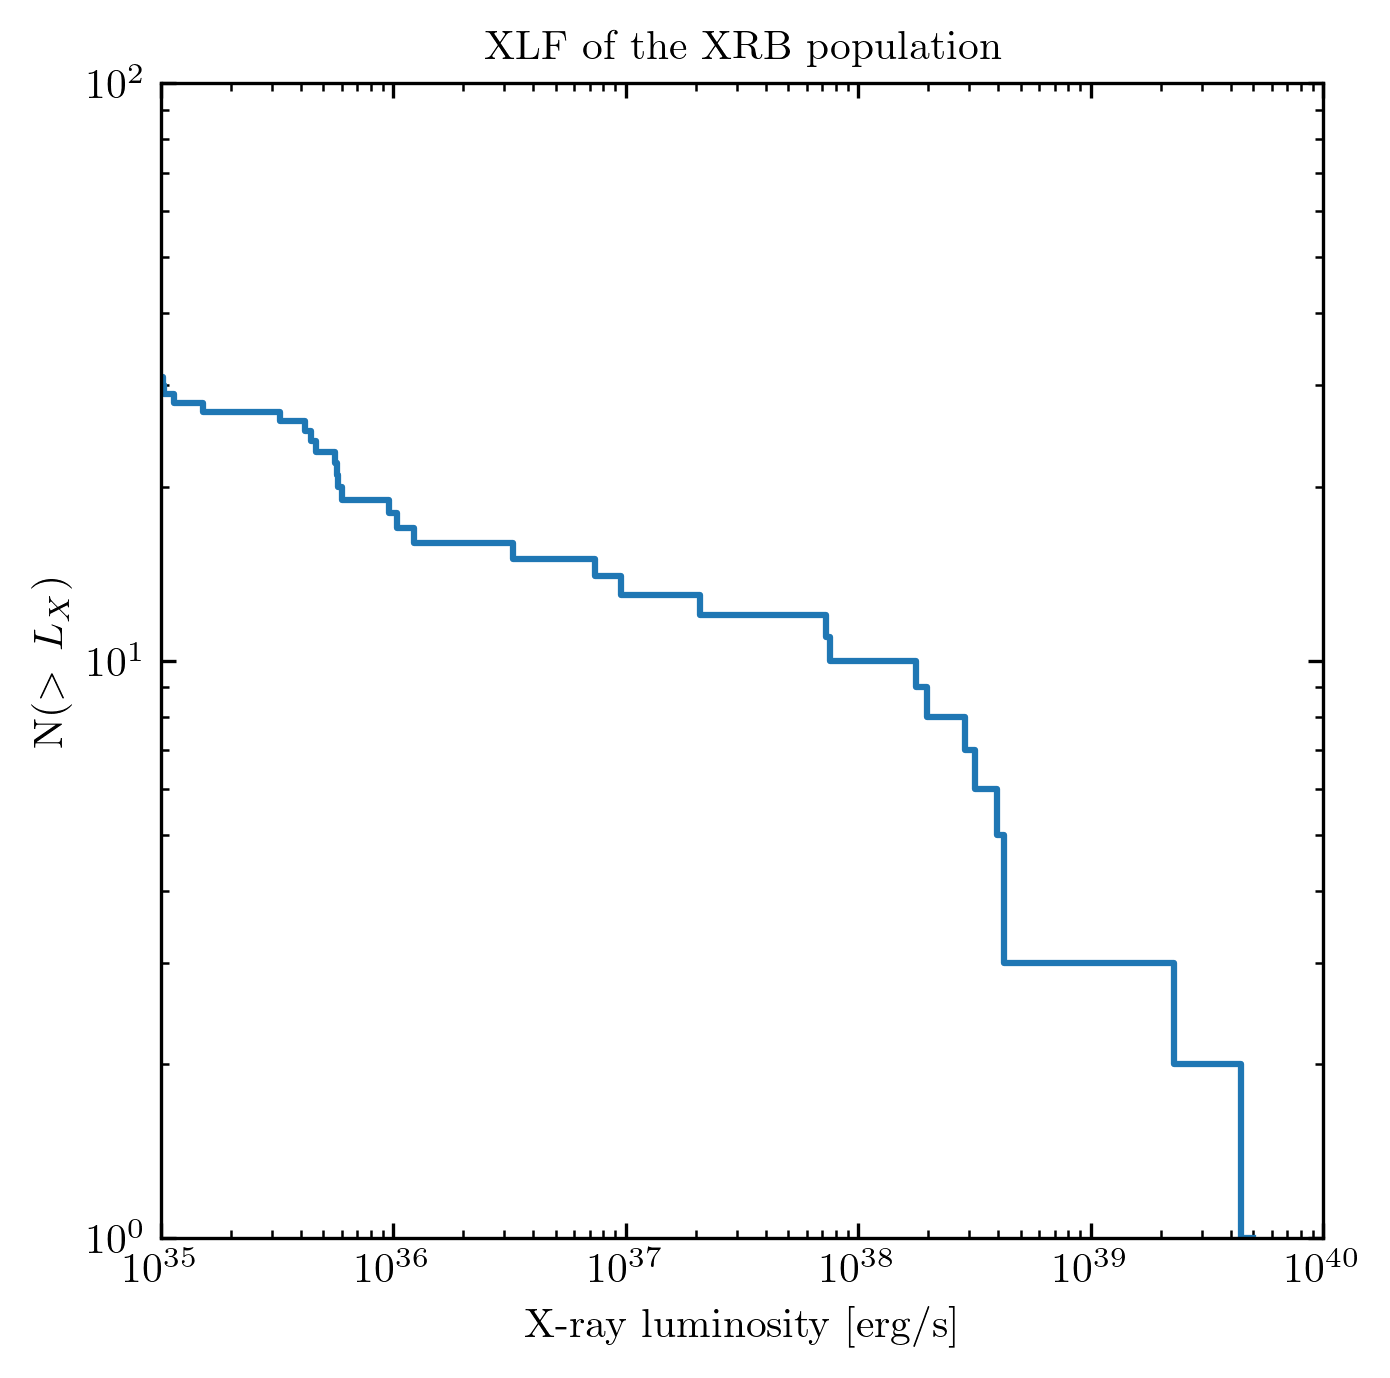

In [9]:
# Write here your code for Excercise 5
L = pd.to_numeric(XRBs.population['Lx_Tot']).to_numpy(dtype=float)

L_min = 1e30 # Given in erg/s


'''As MESA often output -99 for a value that is 0, then we want to get rid of these values. Therefore we apply a a minimal luminosity
to avoid zero values.'''

Mask = (L > L_min)

L = L[Mask]


'''We then sort all the luminosity values according to their value.

np.sort(.) sort by increasing data (so from the smallest value to the biggest)

np.ones_like(table) creates a table with the same length as the given table
    (e.g. : np.ones_like(np.array[1,2,5,10]) will give array([1, 1, 1, 1]))

np.cumsum(array) do a sum of all the elements before the i^th element 
    (e.g. : np.cumsum([1, 3, 8, 9]) results in array([1, 4, 12, 21]))
    and [::-1] reverse the process 
    (e.g. : np.cumsum([1, 3, 8, 9])[::-1] results in array([21, 12, 4, 1]))
'''

L_sorted = np.sort(L) # Sorted luminosities 
N_gt = np.cumsum(np.ones_like(L_sorted, dtype=int))[::-1] # Number of XRBs having a luminosity greater than a given Lx

#----------------Plot----------------
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L_sorted, N_gt)

axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(1, 1e2)
plt.show()



<details>
<summary>Solution of Excercise 5</summary>

~~~python

#Normally, on your own system where LateX is installed, you would load the posydon style like this:
# import matplotlib as mpl
# mpl.style.use(PATH_TO_POSYDON + 'posydon/visualization/posydon.mplstyle')

# But since LateX may not be installed or configured properly on this system, 
# we will ignore the posydon style for now and just prevent LaTeX usage:
import matplotlib as mpl
mpl.rcParams['text.usetex'] = False  # prevent LaTeX usage




L = pd.to_numeric(XRBs.population['Lx_tot']).to_numpy(dtype=float)

L_min = 1e30  # erg/s

# MESA often outputs -99 for for log values of quantities that are zero. We can filter those out, 
# by setting a minimum value for the X-ray luminosity that we consider.
L = L[(L > L_min)]

# The easiest way to compute the cumulative distribution is to sort the luminosities 
# and then use cumsum and invert the order.
L_sorted = np.sort(L)
N_gt = np.cumsum(np.ones_like(L_sorted, dtype=int))[::-1]

fig, axs = plt.subplots(figsize=(5,5))


axs.step(L_sorted, N_gt)
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity (erg/s)')
axs.set_ylabel('N(>Lx)')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(1, 1e2)
plt.show()


~~~~
<details>

### 3.1  A proper normalisation of our simulated XLF

The Y axis of our XLF is rather arbitrary. Had we run a population of 10 titmes more binaries, we would have 10 times more XRBs. In order to compare with observations, it is best to normalise our XLF to something physical. For XLFs of star forming galaxies the normalisation of the Y axis is usually per unit of star formation rate $[M_\odot/yr]$. 

In POSYDON, there is a function that gives us the probability of each of the modeled systems in our population per unit of stellar mass. This function is very flexible allowing us to reweight these probabilities, for distributions of initial binary property distribution, different than the ones we had initially used in our population run. 

Here, we will use it in its simplest form. In our population run, we only modeled systems with primary masses above $7\,\rm M_\odot$ (```primary_mass_min = 7, primary_mass_max = 150```), as we did not want to waste cpu time to model binaries that we know would not form XRBs. However, in order to properly calculate the probability of each modeled binary per unit of stellar mass, we would need to extend the IMF of the primary, say down to $0.6\,\rm M_\odot$. Here how this is done:

In [10]:
# We make a copy of the initial population parameters and change the minimum primary mass to 0.6 Msun
# This is needed for the reweighting to a full IMF down to low masses.
pop_params = XRBs.ini_params.copy()
pop_params['primary_mass_min'] = 0.6

weights = XRBs.calculate_model_weights(model_weights_identifier="base_IMF", population_parameters=pop_params)

# These weights have unit of 1/Msun, and give the probability of each modeled system per unit of stellar mass formed in stars.
weights

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power


,base_IMF
0,5.748304e-07
1,5.748304e-07
2,5.748304e-07
3,5.748304e-07
4,5.748304e-07
...,...
8130,5.748304e-07
8131,5.748304e-07
8132,5.748304e-07
8133,5.748304e-07


### Excercise 6

Let's now properly normalise our XLF, to be per unit of star formation rate. Remember that when we are talking about star formation rate in astronomy, there is always an implicit assumption about the star formation history of the population. The most common, and then one that we assume here is a constant star formation rate over the last 100 Myr. 

Use the weights we calculated above and our assumption of constant star formation rate over the last 100 Myr, to normalise our XLF.

<details>
<summary>Tip</summary>

Calculate how much stellar mass is formed over 100 My with a constant star formation of $1 M_\odot / yr$ and multiply the calculated weight with this number. This will make them a proper unitless weight.

In the previous excercise, for the Y  axis, you created an array of equal lenght to L, which you filled with ones. Now you should use the weights array instead.

Don't forget to convert the weights to a numpy array as well.

</details>

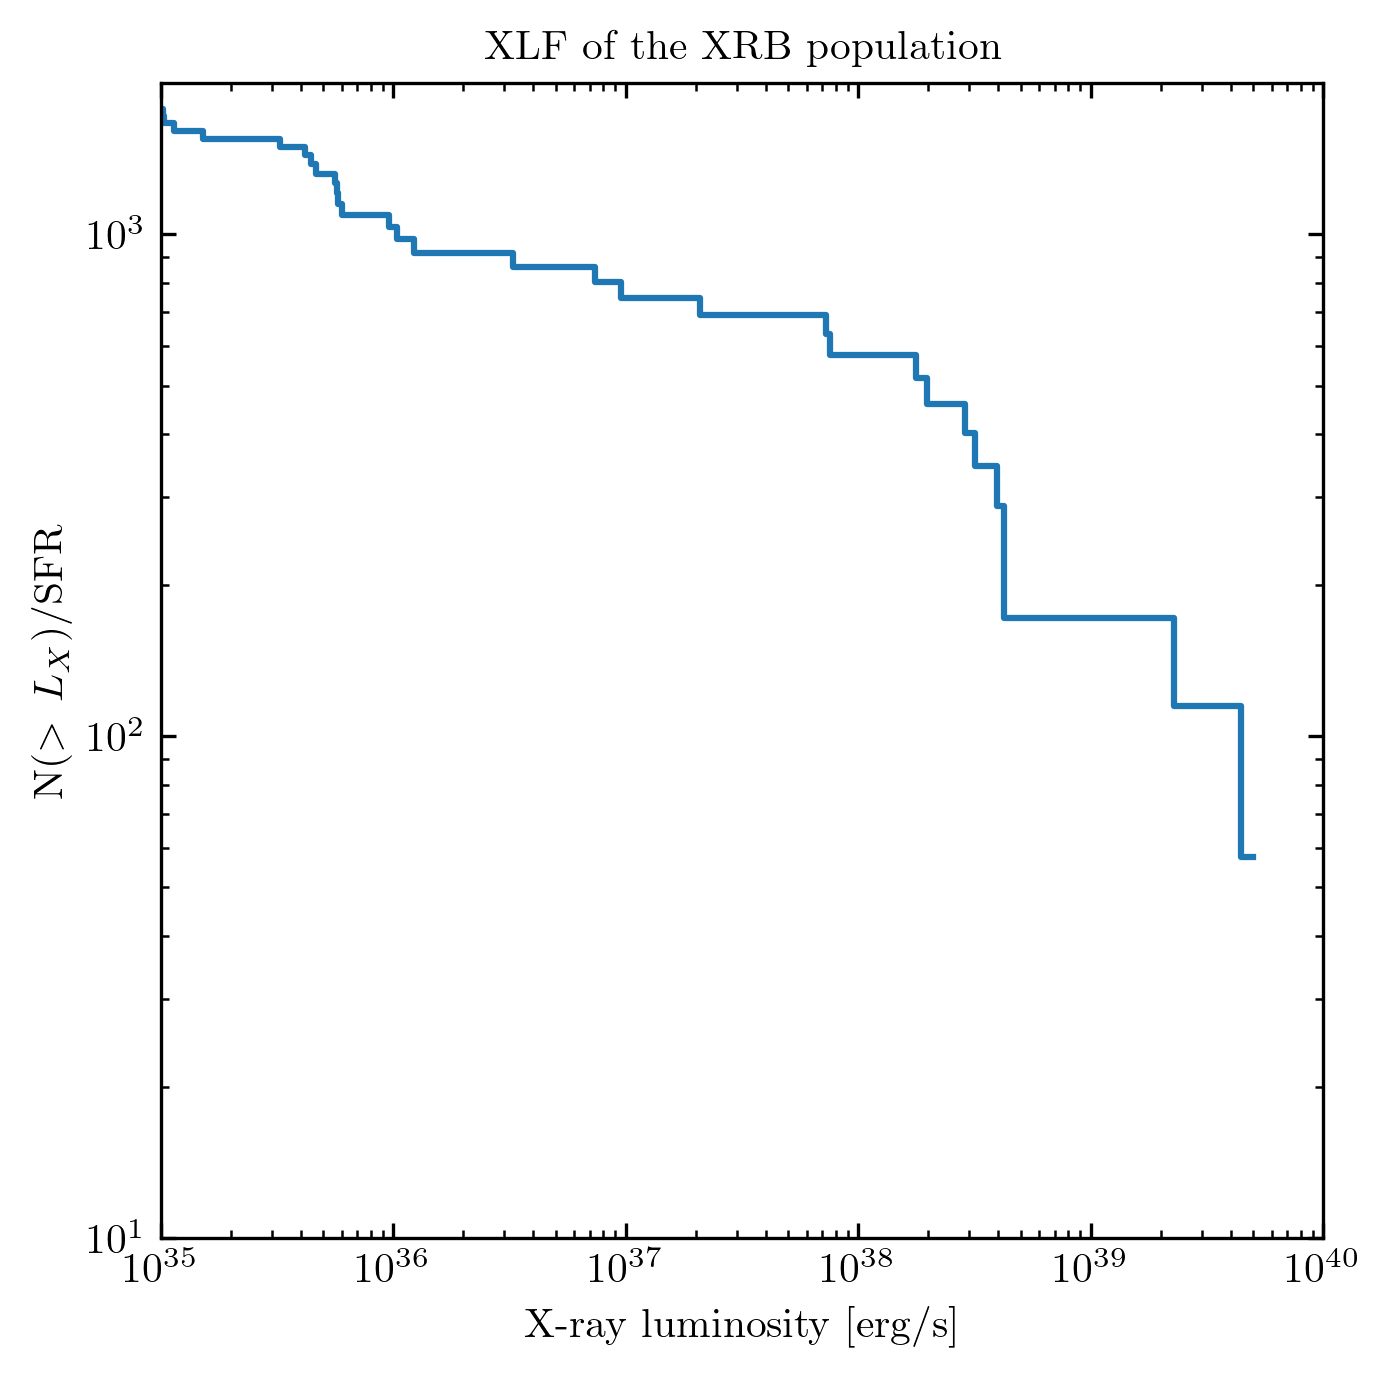

In [11]:
# Write here your code for Excercise 6
L = pd.to_numeric(XRBs.population['Lx_Tot']).to_numpy(dtype=float)

L_min = 1e30 # Given in erg/s

Total_underlying_mass = 1e8 #Msun  -  1 Msolar/yr * 1e8 yr

'''As MESA often output -99 for a value that is 0, then we want to get rid of these values. Therefore we apply a a minimal luminosity
to avoid zero values.'''

Mask = (L > L_min)

L_masked = L[Mask]
weights_masked = weights.to_numpy(dtype = float)[Mask]


'''We then sort all the luminosity values according to their value.

np.sort(.) sort by increasing data (so from the smallest value to the biggest)

np.ones_like(table) creates a table with the same length as the given table
    (e.g. : np.ones_like(np.array[1,2,5,10]) will give array([1, 1, 1, 1]))

np.cumsum(array) do a sum of all the elements before the i^th element 
    (e.g. : np.cumsum([1, 3, 8, 9]) results in array([1, 4, 12, 21]))
    and [::-1] reverse the process 
    (e.g. : np.cumsum([1, 3, 8, 9])[::-1] results in array([21, 12, 4, 1]))
'''

L_sorted = np.sort(L_masked) # Sorted luminosities 
weights_sorted = weights_masked[np.argsort(L_masked)]
N_gt = np.cumsum(weights_sorted)[::-1] * Total_underlying_mass # Number of XRBs having a luminosity greater than a given Lx

#----------------Plot----------------
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L_sorted, N_gt)

axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)/SFR')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(10, 2e3)
plt.show()



<details>
<summary>Solution of Excercise 6</summary>

~~~python

#Normally, on your own system where LateX is installed, you would load the posydon style like this:
# import matplotlib as mpl
# mpl.style.use(PATH_TO_POSYDON + 'posydon/visualization/posydon.mplstyle')

# But since LateX may not be installed or configured properly on this system, 
# we will ignore the posydon style for now and just prevent LaTeX usage:
import matplotlib as mpl
mpl.rcParams['text.usetex'] = False  # prevent LaTeX usage


Total_underlying_mass = 1e8 #Msun  -  1 Msolar/yr * 1e8 yr

L = pd.to_numeric(XRBs.population['Lx_tot']).to_numpy(dtype=float)

L_min = 1e30  # erg/s

# MESA often outputs -99 for for log values of quantities that are zero. We can filter those out, 
# by setting a minimum value for the X-ray luminosity that we consider.
L_masked = L[(L > L_min)]
weights_masked = weights.to_numpy(dtype=float)[(L > L_min)]

# The easiest way to compute the cumulative distribution is to sort the luminosities 
# and then use cumsum and invert the order.
L_sorted = np.sort(L_masked)
weights_sorted = weights_masked[np.argsort(L_masked)]
N_gt = np.cumsum(weights_sorted)[::-1]* Total_underlying_mass

fig, axs = plt.subplots(figsize=(5,5))



axs.step(L_sorted, N_gt)
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity (erg/s)')
axs.set_ylabel('N(>Lx)/SFR')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(10, 2e3)
plt.show()

~~~

<datails>

### Excercise 7

Now, as a final excercise, let's try to explore a bit further the XLF by spliting it into subpopulations, depending on the type of the accretor (NS or BH), and the type of mass-transfer (RLO or wind-fed).

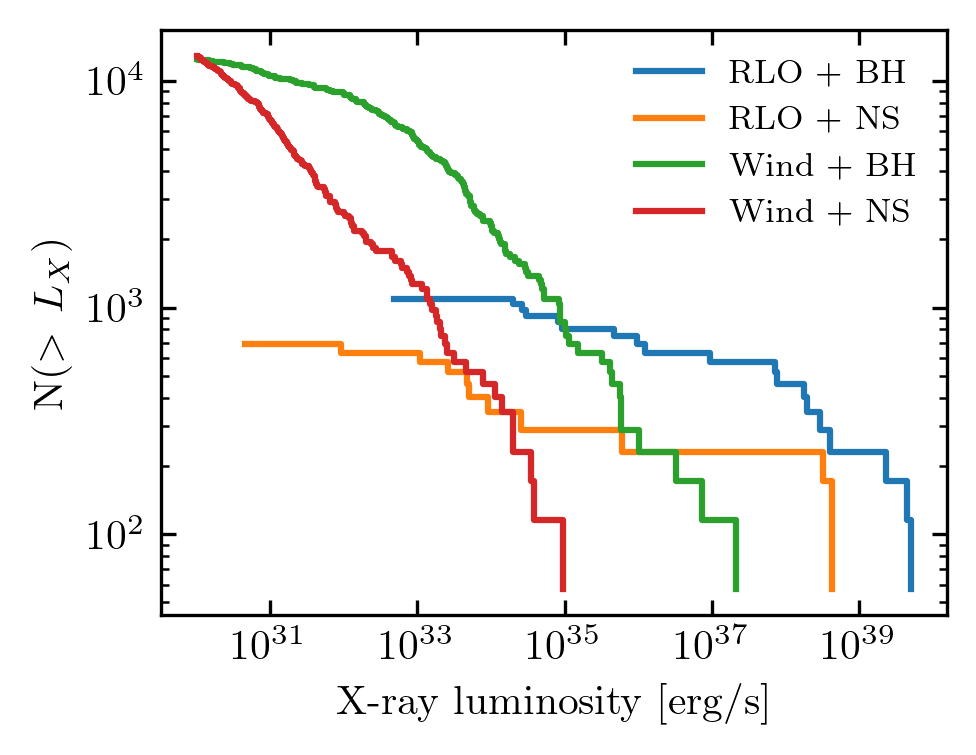

In [ ]:
# Write here your code for Excercise 7

# Getting the info on if the accretor is a neutron star of black hole and checking if accretion is through RLO or winds

BH = XRBs.population['Accretor state'] == 'BH' # True/False pandas series
NS = XRBs.population['Accretor state'] == 'NS' # True/False pandas series
RLO = (XRBs.population['Lx_RLO'] > XRBs.population['Lx_BHL']) & (XRBs.population['Lx_RLO'] > L_min) # True/False pandas series
Wind = (XRBs.population['Lx_BHL'] > XRBs.population['Lx_RLO']) & (XRBs.population['Lx_BHL'] > L_min) # True/False pandas series




def plot_ccdf(vals, weight, label):
    x = np.sort(vals)                    # ascending
    y = np.cumsum(weight[np.argsort(vals)])[::-1]   # N(>x)
    plt.step(x, y, where='post', label=label)

plt.figure()
plot_ccdf(XRBs.population.loc[RLO  & BH, 'Lx_Total'].to_numpy(), weights[RLO  & BH].to_numpy() * Total_underlying_mass, 'RLO + BH')
plot_ccdf(XRBs.population.loc[RLO  & NS, 'Lx_Total'].to_numpy(), weights[RLO  & NS].to_numpy() * Total_underlying_mass, 'RLO + NS')
plot_ccdf(XRBs.population.loc[Wind & BH, 'Lx_Total'].to_numpy(), weights[Wind & BH].to_numpy() * Total_underlying_mass, 'Wind + BH')
plot_ccdf(XRBs.population.loc[Wind & NS, 'Lx_Total'].to_numpy(), weights[Wind & NS].to_numpy() * Total_underlying_mass, 'Wind + NS')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('X-ray luminosity [erg/s]')
plt.ylabel('N($>\, L_{X}$)')
plt.legend()
plt.show()



<details>
<summary>Solution of Excercise 7</summary>

~~~python

Total_underlying_mass = 1e8 #Msun  -  1 Msolar/yr * 1e8 yr


L_min = 1e30  # erg/s
#mask_valid = np.isfinite(Lx_tot) & (Lx_tot > L_min)

# Accretor type masks
is_bh = XRBs.population['accretor_state'] == 'BH'
is_ns = XRBs.population['accretor_state'] == 'NS'

# Accretion mode masks
# RLO if RLO luminosity > BHL luminosity
is_rlo = (XRBs.population['Lx_rlo'] > XRBs.population['Lx_bhl']) & (XRBs.population['Lx_rlo'] > L_min)
is_wind = (XRBs.population['Lx_rlo'] < XRBs.population['Lx_bhl']) & (XRBs.population['Lx_bhl'] > L_min)



def plot_ccdf(vals, w, label):
    x = np.sort(vals)                    # ascending
    y = np.cumsum(w[np.argsort(vals)])[::-1]   # N(>x)
    plt.step(x, y, where='post', label=label)

plt.figure()
plot_ccdf(XRBs.population.loc[is_rlo  & is_bh, 'Lx_tot'].to_numpy(), weights[is_rlo  & is_bh].to_numpy()*Total_underlying_mass, 'RLO + BH')
plot_ccdf(XRBs.population.loc[is_rlo  & is_ns, 'Lx_tot'].to_numpy(), weights[is_rlo  & is_ns].to_numpy()*Total_underlying_mass, 'RLO + NS')
plot_ccdf(XRBs.population.loc[is_wind & is_bh, 'Lx_tot'].to_numpy(), weights[is_wind & is_bh].to_numpy()*Total_underlying_mass, 'Wind + BH')
plot_ccdf(XRBs.population.loc[is_wind & is_ns, 'Lx_tot'].to_numpy(), weights[is_wind & is_ns].to_numpy()*Total_underlying_mass, 'Wind + NS')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('X-ray luminosity (erg/s)')
plt.ylabel('N(>Lx)')
plt.legend()
plt.show()

~~~

<details>

### (Optional) Excercise 8

Compare your simulated XLFs and observed on, e.g. Figure 3 in [Lehmer et al. (2021)](https://arxiv.org/pdf/2011.09476). Do you see any similarities? Do you see any obvious discrepancies? In Figure 3 of [Lehmer et al. (2021)](https://arxiv.org/pdf/2011.09476) you also see the dependence of the XLF to metallicity. You can load a second populations that is available to you at 10% Solar metallicity and see if a similar trend appears in your simulated XLFs. Can you speculate what might be the reason of the dependence of the XLF shape to metallicity?

## 4.Test

### 4.0 Extraction data

In [3]:
import posydon.utils.constants as const

In [ ]:
import numpy as np

def orbital_separation_from_period(Mass1, Mass2, period_days):
    """
    Calculate the orbital separation *a* given the period of the system from the 3rd Kepler's law. 
    
    Parameters 
    ---------
    Mass1 : float 
        Mass of the central body/accretor where Mass1 > Mass2 in [M⊙]
    Mass2 : float
        Mass of the orbiting object/donor where Mass2 < Mass1 in [M⊙]
    period_days : float 
        Period of the orbiting companion in [days]
    
    Return
    ------
    a_cm : float 
        Orbital separation of the binary system in [cm]
    """
    period_seconds = period_days * const.day2sec
    M1_gr = Mass1 * const.Msun
    M2_gr = Mass2 * const.Msun
    a_cm = (const.standard_cgrav * (M1_gr + M2_gr) * period_seconds**2 /(4 * np.pi**2))**(1/3) # [cm]
    
    return a_cm

def Get_velocities(Macc, M_donor_Msun, R_donor_Rsun, orbital_period_days, **kwargs):
    """
    Compute different velocities :

    - Relative velocity of a wind emitted form a companion star including orbital + esacpe velocity of the companion
    - Orbital velocity of the companion/donor star
    - Wind velocity if we suppose that the required velocity to be unbound is > escape velocity

    Parameters
    ----------
    Macc : float
        Mass of the accretor in [M⊙]
    M_donor_Msun : float
        Donor mass given in [M⊙] 
    R_donor_Rsun : float
        Donor radius given in [R⊙]
    orbital_period_days : float
        Orbital period of the binary system in [days]
    **kwargs : dict, optional
        Additional keyword arguments:
        - scale (float, default=2.6) : multiplicative factor for wind speed (≥ 1.0).

        Any unknown keys will raise a TypeError.
        
    Return
    ------
    V_rel : float
        Relative velocitiy accoring to the central object/accretor [cm/s] 
    V_orb : float
        Orbital velocity of the donor star [cm/s]
    V_wind : float
        Wind velocity from the donor to the accretor [cm/s]

    References
    ----------
    Frank, J., King, A., & Raine, D. (2002). "Accretion Power in Astrophysics: Third Edition" Chapter 4.9 pages 73-74.
    Cambridge University Press. https://doi.org/10.1017/CBO9781139164417
    """
    #===== Optional parameters =====
    scale = kwargs.pop('scale', 2.6)
    if scale < 1.0:
        raise ValueError("scale must be >= 1.0")
    if kwargs:
        raise TypeError(f"Get_velocities: unknown parameter(s): {list(kwargs.keys())}")
    
    #===== Velocities calculation =====
    M_donor_gr = M_donor_Msun * const.Msun # [gr]
    R_donor_cm = R_donor_Rsun * const.Rsun # [cm]
    a_cm = orbital_separation_from_period(Macc, M_donor_Msun, orbital_period_days) #[cm]

    # Escape and wind velocities
    V_esc = np.sqrt(2 * const.standard_cgrav * M_donor_gr / max(R_donor_cm, 1e-10)) # [cm/s]
    V_wind = scale * V_esc  # [cm/s] rescaling

    # Orbital velocity 
    V_orb = 2 * np.pi * a_cm / (float(orbital_period_days) * const.day2sec) # [cm/s]
    # Relative velocity 
    V_rel = np.sqrt(V_wind ** 2 + V_orb ** 2) # [cm/s]

    return V_rel, V_orb, V_wind

def BHL_mdot_acc(M_acc_Msun, Mdot_w_Msun_per_yr, a_cm, v_rel_cms, **kwargs):
    """
    Calculate the Bondi-Hoyle Littleton accretion rate through winds in gram per second.

    Parameters
    ----------
    M_acc_Msun : float 
        Mass of the accretor in [M⊙]
    Mdot_w_Msun_per_yr : float
        Accretion rate from winds in [M⊙/yr]
    a_cm : float
        Orbital separation of the binary system in [cm]
    v_rel_cms : float
        Relative velocity of the accreted material in [cm/s]
        This relative velocity is a combination of the wind speed and orbital velocity
    **kwargs : dict, optional
        Additional keyword arguments:
        - alpha_BHL (float, default = 1.0) : Alpha parameter of Bondi-Hoyle Littleton (alpha_BHL ∈ [1, 2]).

        Any unknown keys will raise a TypeError.

    Return
    ------
    Mdot_w : float 
        Accretion rate through winds in [gr/s]  
    """
     #===== Optional parameters =====
    alpha_BHL = kwargs.pop('alpha_BHL', 1.0) # Alpha parameter of Bondi-Hoyle Littleton
    if alpha_BHL < 1.0 or alpha_BHL > 2.0:
        raise ValueError("alpha_BHL must be in the range [1, 2]")
    if kwargs:
        raise TypeError(f"BHL_mdot_acc: unknown parameter {list(kwargs.keys())}")
    
    #===== Calculation =====
    Macc = float(M_acc_Msun) * const.Msun # [gr]
    
    # Accreted material from winds
    Mdot_w_gr_per_sec = float(max(Mdot_w_Msun_per_yr, 0.0)) * const.Msun / const.secyer  # [g/s]
    Vrel_power_4 = max(v_rel_cms, 1.0)**4
    Sep_power_2 = max(a_cm, 1.0)**2

    frac = alpha_BHL * (const.standard_cgrav**2 * Macc**2) / (Sep_power_2 * Vrel_power_4)
    return frac * Mdot_w_gr_per_sec  # g/s

def BH_efficiency(mass, spin, dimensional_spin = False): 
    """
    Compute the radiative efficiency of a Kerr black hole (or Schwarzchild BH if spin = 0)
    as a function of the spin parameter *a* and the mass according to Novikov-Thorne radiative efficiency.

    Parameters
    ---------- 
    mass : float
        mass of the central black hole in Msun
    spin : float
        Spin of the black hole. Can be given as dimensionless spin "a*" or dimensional spin "a" in [cm].
        Its value can be given either positively (prograde accretion) or negatively (retrograde accretion) 
        (spin  ∈ [-0.998, 0.998] with ± 0.998 being the Thorne limit).
    dimensional_spin : bool, optional 
        If True, convert dimensional spin "a" to dimentionless spin "a*".

    Returns
    -------
    tuple
        A tuple with three floats: (E_ISCO, r_tilde, eta).
        - E_ISCO (float): Specific energy at the ISCO, in units of m c^2.
        - r_tilde (float): Radius of the ISCO in units of G M / c^2.
        - eta (float): Radiative efficiency (1 - E_ISCO), dimensionless.
        
    References
    ----------
    Bambi, C., Malafarina, D., & Tsukamoto, N. (2014),
    "Note on the radiation emitted by a thin accretion disk around a rotating compact object",
    Phys. Rev. D, 89(12), 127302. https://arxiv.org/abs/1406.2181
    """
   
    if  mass < 0 : 
        raise ValueError("Mass must be positive")

    M = mass * const.Msun # [gr]

    # Conversion to dimensionless spin
    if dimensional_spin:
        a_star = const.clight * spin/(const.standard_cgrav * M)
    else: 
        a_star = float(spin)
    
    # To control that the spin is in the range that gives the maximal efficiency
    a_star = float(np.clip(a_star, -0.998, 0.998))

    #=== Compute efficiency === 
    
    # Use sign = +1 for spin ≥ 0 (prograde) and -1 otherwise (retrograde)
    sign = 1 if a_star >= 0 else -1

    Z1 = 1 + (1 - a_star**2)**(1/3) * ((1 + a_star)**(1/3) + (1 - a_star)**(1/3))
    Z2 = np.sqrt(3 * a_star**2 + Z1**2)

    # Radius at the innermost stable circular orbit (ISCO)
    r_tilde = 3 + Z2 - sign * np.sqrt((3 - Z1)*(3 + Z1 + 2 * Z2)) # Dimensionless

    # Energy at ISCO in units of mc^2 (i.e E_ISCO < 1, E = 1 means particle energy at infinity)
    E_ISCO = (r_tilde**(3/2) - 2 * r_tilde**(1/2) + a_star)/(r_tilde**(3/4) * np.sqrt(r_tilde**(3/2) - 3 * r_tilde**(1/2) + 2 * a_star))
    
    # Radiative efficiency
    eta = 1 - E_ISCO
    return E_ISCO, r_tilde, eta

def NS_efficiency(mass,log_radius):
    """
    Compute the radiative efficiency of a neutron star as a function of its mass and radius.

    Parameters
    ----------
    mass : float
        Mass of the neutron star in [M⊙]
    log_radius : float
        Log10(Radius of the neutron star) in [R⊙]

    Returns
    -------
    eta : float
        Radiative efficiency of the neutron star, dimensionless.
    """
    #===== Mass =====
    if mass is None or not np.isfinite(mass) or mass <= 0.0:
            mass = 1.45 # Default mass of a NS in [M⊙]
    
    M = float(mass) * const.Msun # [gr]

    #===== Radius =====
    if log_radius is None or not np.isfinite(log_radius):
            # fallback radius ~10 km -> 1e6 cm
            acc_r_cm = 1e6
    else:
            acc_r_sun = 10.0**float(log_radius)   # [R⊙]
            acc_r_cm = acc_r_sun * const.Rsun # [cm]

    #===== Efficiency computation =====
    eta = const.standard_cgrav * M /(acc_r_cm * const.clight**2) # dimensionless ~0.1-0.3
    
    return eta

def Compute_Lx(donor_mass, donor_log_R, accretor_mass, accretor_log_R, accretor_type, 
               donor_log_mdot, log_Mtransfer_rate, accretor_log_mdot,
               H1_content_donor, orbital_period_days, 
               accretor_spin  = 0.0, **kwargs): 
    """
    Compute the X-ray luminosity of a binary system as long as there is a compact accretor
    
    Parameters
    ----------
    donor_mass : float
        Mass of the donor star in [M⊙]
    donor_log_R : float
        Log10(Radius of the donor star) in [R⊙]
    accretor_mass : float
        Mass of the accretor in [M⊙]
    accretor_log_R : float
        Log10(Radius of the accretor) in [R⊙]
    accretor_type : str
        Type of the accretor. Can be either 'NS' or 'BH'
    donor_log_mdot : float
        Log10(Mass loss rate from the donor star) in [M⊙/yr]. Is the total mass loss rate from the donor star including both RLO and winds.
    log_Mtransfer_rate : float
        Log10(Mass transfer rate) in [M⊙/yr]. A fraction of donor_log_mdot.
    accretor_log_mdot : float
        Log10(Mass accretion rate onto the accretor) in [M⊙/yr]. Is the total mass accretion rate onto the accretor including both RLO and winds.
    H1_content_donor : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    orbital_period_days : float
        Orbital period of the binary system in [days] initially set a 15 days. If not given, wind accretion cannot be computed.
    accretor_spin : float
        Spin of the accretor in the case of BH accretor. Initially set at 0.0 (non spinning BH (Schwarzchild)).
    **kwargs : dict, optional
        Additional keyword arguments:
        - scale (float, default=2.6) : multiplicative factor for wind speed (≥ 1.0).
        - alpha_bhl (float, default=1.0) : efficiency parameter for Bondi-Hoyle-Lyttleton accretion.

        Any unknown keys will raise a TypeError.

    Returns
    -------
    tuple
        A tuple with five floats: (Lx_total, Lx_RLO, Lx_BHL, beaming_RLO, beaming_BHL, Edd_state).
        - Lx_total (float): Total X-ray luminosity of the binary system in [erg/s].
        - Lx_RLO (float): X-ray luminosity from Roche lobe overflow in [erg/s].
        - Lx_BHL (float): X-ray luminosity from Bondi-Hoyle-Littleton wind accretion in [erg/s].
        - beaming_RLO (float): Beaming factor for the X-ray luminosity from Roche lobe overflow.
        - beaming_BHL (float): Beaming factor for the X-ray luminosity from Bondi-Hoyle-Littleton wind accretion.
        - Edd_state (str): Description of the Eddington accretion state of the system.

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           arXiv:2209.05505v2  
           https://arxiv.org/abs/2209.05505v2 
    """
    #===== Optional parameters =====
    scale = kwargs.pop('scale', 2.6) # Scale parameter to rescale
    alpha_bhl = kwargs.pop('alpha_bhl', 1.0) # Alpha parameter of Bondi-Hoyle Littleton
    if scale < 1.0:
        raise ValueError("scale must be >= 1.0")
    if kwargs:
        # catch typos / unexpected options early
         raise TypeError(f"Compute_Lx: unknown parameter(s): {list(kwargs.keys())}")

    #===== Efficiency according to CO ===== 
    if accretor_type == 'NS':
        eta = NS_efficiency(accretor_mass, accretor_log_R)
    elif accretor_type == 'BH':
        _, _, eta = BH_efficiency(accretor_mass, accretor_spin)
    else:
        return np.nan, np.nan, np.nan # Non compact accretor case
    
    if not np.isfinite(eta) or eta <= 0.0:
        eta = 1e-6 # Protect against zero or non-finite efficiency

    #===== Rates RLO/Winds ======
    # Mass-transfer rate (donor -> vicinity of accretor)[Msun/yr]
    M_tr_Msunyr = 0.0 if log_Mtransfer_rate is None or not np.isfinite(log_Mtransfer_rate) else 10.0**float(log_Mtransfer_rate)

    # Accreted mass [Msun/yr]
    if accretor_log_mdot is None or not np.isfinite(accretor_log_mdot):
        M_acc_Msunyr = M_tr_Msunyr  # All transfered material is accreted
    else:
        M_acc_Msunyr = 10.0**float(accretor_log_mdot)

    # Donor mass loss rate (total, including RLO + winds) [Msun/yr]
    Mdot_donor_total_Msunyr = 0.0 if donor_log_mdot is None or not np.isfinite(donor_log_mdot) else 10.0**float(donor_log_mdot)
    mdot_wind_only_Msunyr = max(Mdot_donor_total_Msunyr - M_tr_Msunyr, 0.0)

    M_acc_gps = M_acc_Msunyr * const.Msun / const.secyer # [g/s]
    M_tr_gps = M_tr_Msunyr * const.Msun / const.secyer # [g/s]

    # BHL accretion computed from wind-only mass-loss
    a = orbital_separation_from_period(donor_mass, accretor_mass, orbital_period_days)
    V_rel, _, _ = Get_velocities(accretor_mass, donor_mass, 10.0**donor_log_R, orbital_period_days, scale=scale)
    Mdot_BHL_gps = BHL_mdot_acc(accretor_mass, mdot_wind_only_Msunyr, a, V_rel, alpha_BHL=alpha_bhl)

    #===== Eddington mass flux =====
    if H1_content_donor is None or not np.isfinite(H1_content_donor) or H1_content_donor < 0.0 or H1_content_donor > 1.0:
        H1_content_donor = 0.7155 # Default H1 content of a MS star

    Mdot_Edd_gps = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun / (0.2 * (1.0 + H1_content_donor) * const.clight * eta) # [g/s]

    if not np.isfinite(Mdot_Edd_gps) or Mdot_Edd_gps <= 0.0:
        Mdot_Edd_gps = 1e-99

    beaming_RLO = 1.0 # Default beaming factor
    beaming_BHL = 1.0 # Default beaming factor
    beaming = 1.0 # Default beaming factor

    # Eddington ratio and on computed BHL
    m_dot_tr = (M_tr_gps / Mdot_Edd_gps)
    m_dot_bhl = (Mdot_BHL_gps / Mdot_Edd_gps) if np.isfinite(Mdot_BHL_gps) else 0.0
    
    # Eddington state
    Edd_state = []
    if m_dot_tr > 1.0 and m_dot_bhl > 1.0:
        Edd_state = 'Super-Eddington RLO + BHL'
    elif m_dot_tr < 1.0 and m_dot_bhl < 1.0:
        Edd_state = 'Sub-Eddington RLO + BHL'
    else: 
        Edd_state = 'Mixed Eddington RLO + BHL'

    # ===== L_RLO =====
    if m_dot_tr <= 1.0:
        # sub-Eddington: use actual accreted mass if available, else M_tr
        Lx_RLO = eta * M_acc_gps * const.clight**2 if M_acc_gps > 0.0 else 0.0
        beaming_RLO = beaming_RLO
    else:
        # super-Edd: use prescription based on m_dot_tr
        L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight / (0.2 * (1.0 + H1_content_donor))
        if m_dot_tr > 8.5:
            Lx_RLO = L_edd * (m_dot_tr**2 / 73.0) * (1.0 + np.log(m_dot_tr))
            beaming_RLO = min(73.0 / m_dot_tr**2, beaming)
        else:
            Lx_RLO = L_edd * (1.0 + np.log(m_dot_tr))
            beaming_RLO = beaming

    # ===== L_BHL =====
    if (Mdot_BHL_gps is None) or (not np.isfinite(Mdot_BHL_gps)) or (Mdot_BHL_gps <= 0.0):
        Lx_BHL = 0.0
    else:
        if m_dot_bhl <= 1.0:
            Lx_BHL = eta * Mdot_BHL_gps * const.clight**2
            beaming_BHL = beaming
        else:
            L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight / (0.2 * (1.0 + H1_content_donor))
            if m_dot_bhl > 8.5:
                Lx_BHL = L_edd * (m_dot_bhl**2 / 73.0) * (1.0 + np.log(m_dot_bhl))
                beaming_BHL = min(73.0 / m_dot_bhl**2, beaming)
            else:
                Lx_BHL = L_edd * (1.0 + np.log(m_dot_bhl))
                beaming_BHL = beaming

    Lx_total = float(Lx_RLO + Lx_BHL) 
    

    return float(Lx_total), float(Lx_RLO), float(Lx_BHL), beaming_RLO, beaming_BHL, Edd_state

def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk = None, **kwargs):
    '''
    A XRB selection function to create a population of XRBs, where we store some important information.
    This function identifies X-ray binaries as an accretor and a donor star.

    Parameters
    ----------
    history_chunk : pd.DataFrame
        A chunk of the history DataFrame from population class binaries. 
        Specific lines need to be provided. 
    oneline_chunk : pd.DataFrame
        A chunk of the oneline DataFrame from population class binaries.
    formation_channels_chunk : pd.DataFrame, optional
        A chunk of the formation channels DataFrame of the binaries. Default is None.
    **kwargs : dict, optional
        Additional arguments passed to Compute_Lx function.

    Returns
    -------
    DF_XRBs : pd.DataFrame
        A DataFrame containing the selected XRBs with accretor/donor data and XLFs associated to each binary.
    
    '''
    #===== Check inputs =====
    required = [
        'S1_state_f','S2_state_f','S1_mass_f','S2_mass_f',
        'S1_log_R_f','S2_log_R_f','S1_lg_mdot_f','S2_lg_mdot_f',
        'S1_surf_avg_omega_div_omega_crit_f','S2_surf_avg_omega_div_omega_crit_f',
        'S1_spin_f','S2_spin_f','S1_surface_h1_f','S2_surface_h1_f',
        'time_f','time_i','metallicity','orbital_period_f','eccentricity_f','lg_mtransfer_rate_f'
    ]

    missing = [col for col in required if col not in oneline_chunk.columns]
    if missing:
        raise KeyError(f"oneline_chunk missing required columns: {missing}")
    
    #===== Optional parameters **kwargs =====
    scale = kwargs.get('scale', 2.6) # Scale parameter to rescale
    alpha_bhl = kwargs.get('alpha_bhl', 1.0) # Alpha parameter of Bondi-Hoyle Littleton

    #===== Initialization =====
    # Compact objects types for filtering
    Compact_types = {'NS','BH'}
    Objects_to_avoid = {'NS','BH','massless_remnant', 'WD'}
    
    # Masks to identify XRBs
    Star1 = oneline_chunk['S1_state_f']
    Star2 = oneline_chunk['S2_state_f']
    mask1 = (Star1.isin(Compact_types)) & (~Star2.isin(Objects_to_avoid))
    mask2 = (Star2.isin(Compact_types)) & (~Star1.isin(Objects_to_avoid))
    mask = (mask1 | mask2) # Mask to filter out non XRB systems
    oneline_sel = oneline_chunk.loc[mask].copy()
    is_s1_compact = oneline_sel['S1_state_f'].isin(Compact_types)

    # Create an empty Dataframe with indices of the selected binaries
    indices = oneline_sel.index.to_numpy()
    DF_XRBs = pd.DataFrame(index = indices)

    DF_XRBs['time'] = oneline_sel['time_f'] * 1e-6 # Myr
    DF_XRBs['time_of_birth'] = oneline_sel['time_i'] * 1e-6 # Myr
    DF_XRBs['metallicity'] = oneline_sel['metallicity']
    
    #===== Identify accretor/donor and their properties =====
    # Accretor
    DF_XRBs['Accretor_mass'] = np.where(is_s1_compact, oneline_sel['S1_mass_f'], oneline_sel['S2_mass_f'])

    DF_XRBs['Accretor_state'] = np.where(is_s1_compact, oneline_sel['S1_state_f'], oneline_sel['S2_state_f'])

    DF_XRBs['Accretor_log(R)'] = np.where(is_s1_compact, oneline_sel['S1_log_R_f'], oneline_sel['S2_log_R_f'])

    DF_XRBs['Accretor_log(mdot)'] = np.where(is_s1_compact, oneline_sel['S1_lg_mdot_f'], oneline_sel['S2_lg_mdot_f'])

    DF_XRBs['Accretor_spin'] = np.where(is_s1_compact, oneline_sel['S1_spin_f'], oneline_sel['S2_spin_f'])

    # Donor
    DF_XRBs['Donor_mass'] = np.where(is_s1_compact, oneline_sel['S2_mass_f'], oneline_sel['S1_mass_f'])

    DF_XRBs['Donor_state'] = np.where(is_s1_compact, oneline_sel['S2_state_f'], oneline_sel['S1_state_f'])

    DF_XRBs['Donor_log(R)'] = np.where(is_s1_compact, oneline_sel['S2_log_R_f'], oneline_sel['S1_log_R_f'])

    DF_XRBs['Donor_log(mdot)'] = np.where(is_s1_compact, oneline_sel['S2_lg_mdot_f'], oneline_sel['S1_lg_mdot_f'])

    DF_XRBs['Donor_surf_avg_omega_div_omega_crit'] = np.where(is_s1_compact, 
                                                              oneline_sel['S2_surf_avg_omega_div_omega_crit_f'], 
                                                              oneline_sel['S1_surf_avg_omega_div_omega_crit_f'])

    DF_XRBs['Donor_H1_surface_content'] = np.where(is_s1_compact, oneline_sel['S2_surface_h1_f'], oneline_sel['S1_surface_h1_f'])

    #===== Additional parameters related to the system =====
    DF_XRBs['Orbital_period'] = oneline_sel['orbital_period_f'].to_numpy()  # days
    DF_XRBs['Eccentricity'] = oneline_sel['eccentricity_f'].to_numpy()
    DF_XRBs['Log(mtransfer_rate)'] = oneline_sel['lg_mtransfer_rate_f'].to_numpy() # Msun/yr
    
    #===== Calculate XLF for the population =====
    cols = DF_XRBs[['Donor_mass', 'Donor_log(R)', 'Accretor_mass','Accretor_log(R)', 'Accretor_state', 'Log(mtransfer_rate)', 
                    'Donor_log(mdot)', 'Accretor_log(mdot)', 'Orbital_period', 'Accretor_spin', 
                    'Donor_H1_surface_content']].itertuples(index=False, name=None)

    # Store valid results 
    results = []

    # keep track of errors
    error_count = 0
    error_indices = []

    # Indices of the DataFrame
    idxs = DF_XRBs.index.to_numpy()

    # Luminosity calculation loop
    for i, row in enumerate(cols):
        Dm, Dlr, Am, Alr, Atype, log_mt, Dlog, Alog, Op, spin, h1 = row
        # Skip invalid accretor/donor pairs early
        if Atype is None or (not np.isfinite(Dm) and not np.isfinite(Am)):
            results.append((np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))
            continue
        try:
            res = Compute_Lx(
                donor_mass = Dm,
                donor_log_R = Dlr,
                accretor_mass = Am,
                accretor_log_R = Alr,
                accretor_type = Atype,
                log_Mtransfer_rate = log_mt,
                donor_log_mdot = Dlog,
                accretor_log_mdot = Alog,
                orbital_period_days = Op,
                accretor_spin = spin,
                H1_content_donor = h1,
                **kwargs
            )
        except Exception as e:
            error_count += 1
            # store the original DataFrame index for later inspection
            try:
                error_indices.append(idxs[i])
            except Exception:
                pass
            results.append((np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))
            continue

        # Normalize result to tuple of five floats and one string
        if res is None:
            results.append((np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))
        else:
            try:
                # Expect (Lx_total, Lx_RLO, Lx_BHL, beaming_RLO, beaming_BHL, Edd_state)
                if len(res) == 6:
                    results.append((float(res[0]), float(res[1]), float(res[2]), float(res[3]), float(res[4]), res[5]))
                else:
                    # Fallback: put total in first, others nan
                    results.append((float(res), np.nan, np.nan, np.nan, np.nan, None))
            except Exception:
                results.append((np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))

    if error_count:
        # Succinct error display
        print(f"Compute_Lx: {error_count} error(s) in the luminosity calculation (Indices : {error_indices[:10]})")

    Lx_Total, Lx_RLO, Lx_BHL, Beaming_RLO, Beaming_BHL, Edd_state = zip(*results) if results else ([], [], [], [], [], [])

    DF_XRBs['Beaming_RLO'] = Beaming_RLO
    DF_XRBs['Beaming_BHL'] = Beaming_BHL
    DF_XRBs['Edd_state'] = Edd_state
    DF_XRBs['Lx_RLO'] = Lx_RLO
    DF_XRBs['Lx_BHL'] = Lx_BHL
    DF_XRBs['Lx_Total'] = Lx_Total

    return DF_XRBs


In [5]:
from posydon.popsyn.synthetic_population import Population

Zsun01 = './XRB_pop_runs_100K/1e-01_Zsun_population.h5'
Zsun1 = './XRB_pop_runs_100K/1e+00_Zsun_population.h5'

pop01 = Population(Zsun01)
pop1 = Population(Zsun1)

pop01.calculate_formation_channels(mt_history=True)
pop1.calculate_formation_channels(mt_history=True)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Formation channels already exist in the parsed population file!
Channels will be overwriten
Formation channels already exist in the parsed population file!
Channels will be overwriten


In [9]:
XRB_pop01 = pop01.create_transient_population(XRB_selection_function,'XRB01')
XRB_pop1 = pop1.create_transient_population(XRB_selection_function,'XRB1')

overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [10]:
XRB_pop01.population

,time,time_of_birth,metallicity,Accretor_mass,Accretor_state,Accretor_log(R),Accretor_log(mdot),Accretor_spin,Donor_mass,Donor_state,...,Donor_H1_surface_content,Orbital_period,Eccentricity,Log(mtransfer_rate),Beaming_RLO,Beaming_BHL,Edd_state,Lx_RLO,Lx_BHL,Lx_Total
2,100.0,79.773247,0.1,1.787337,NS,-4.745687,-99.0,0.0,8.603118,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,1.196592e-53,0.000000e+00,1.196592e-53
15,100.0,38.116170,0.1,1.277584,NS,-4.745687,-99.0,0.0,6.261532,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,0.000000e+00,8.553209e-54
18,100.0,4.004403,0.1,1.277584,NS,-4.745687,-99.0,0.0,4.825717,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,0.000000e+00,8.553209e-54
25,100.0,45.081058,0.1,1.277584,NS,-4.745687,-99.0,0.0,4.614617,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,0.000000e+00,8.553209e-54
35,100.0,31.689170,0.1,1.277584,NS,-4.745687,-99.0,0.0,5.462658,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,0.000000e+00,8.553209e-54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99930,100.0,53.010067,0.1,1.277584,NS,-4.745687,-99.0,0.0,2.715634,H-rich_Core_H_burning,...,0.74748,0.679418,0.009029,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,2.265150e+29,2.265150e+29
99937,100.0,18.922828,0.1,2.123602,NS,-4.745687,-99.0,0.0,3.366125,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,1.421716e-53,0.000000e+00,1.421716e-53
99970,100.0,69.910553,0.1,1.322272,NS,-4.745687,-99.0,0.0,8.174450,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.852394e-54,0.000000e+00,8.852394e-54
99976,100.0,13.781850,0.1,1.277584,NS,-4.745687,-99.0,0.0,4.266120,H-rich_Core_H_burning,...,0.74748,NaN,NaN,NaN,1.0,1.0,Sub-Eddington RLO + BHL,8.553209e-54,0.000000e+00,8.553209e-54


In [11]:
pop01.oneline[513]

,state_i,event_i,time_i,orbital_period_i,eccentricity_i,lg_mtransfer_rate_i,step_names_i,step_times_i,S1_state_i,S1_mass_i,...,interp_class_CO_HMS_RLO,interp_class_CO_HeMS,interp_class_CO_HeMS_RLO,mt_history_HMS_HMS,mt_history_CO_HMS_RLO,mt_history_CO_HeMS,mt_history_CO_HeMS_RLO,FAILED,WARNING,metallicity
binary_index,,,,,,,,,,,,,,,,,,,,,
513,detached,ZAMS,184458.21033,10.906852,0.0,NaN,initial_cond,0.0,H-rich_Core_H_burning,19.475315,...,unstable_MT,initial_MT,NaN,Last stable RLOF during postMS,Unstable RLOF during postMS,Initial RLOF,NaN,0,1,0.1


### 4.1 Plots

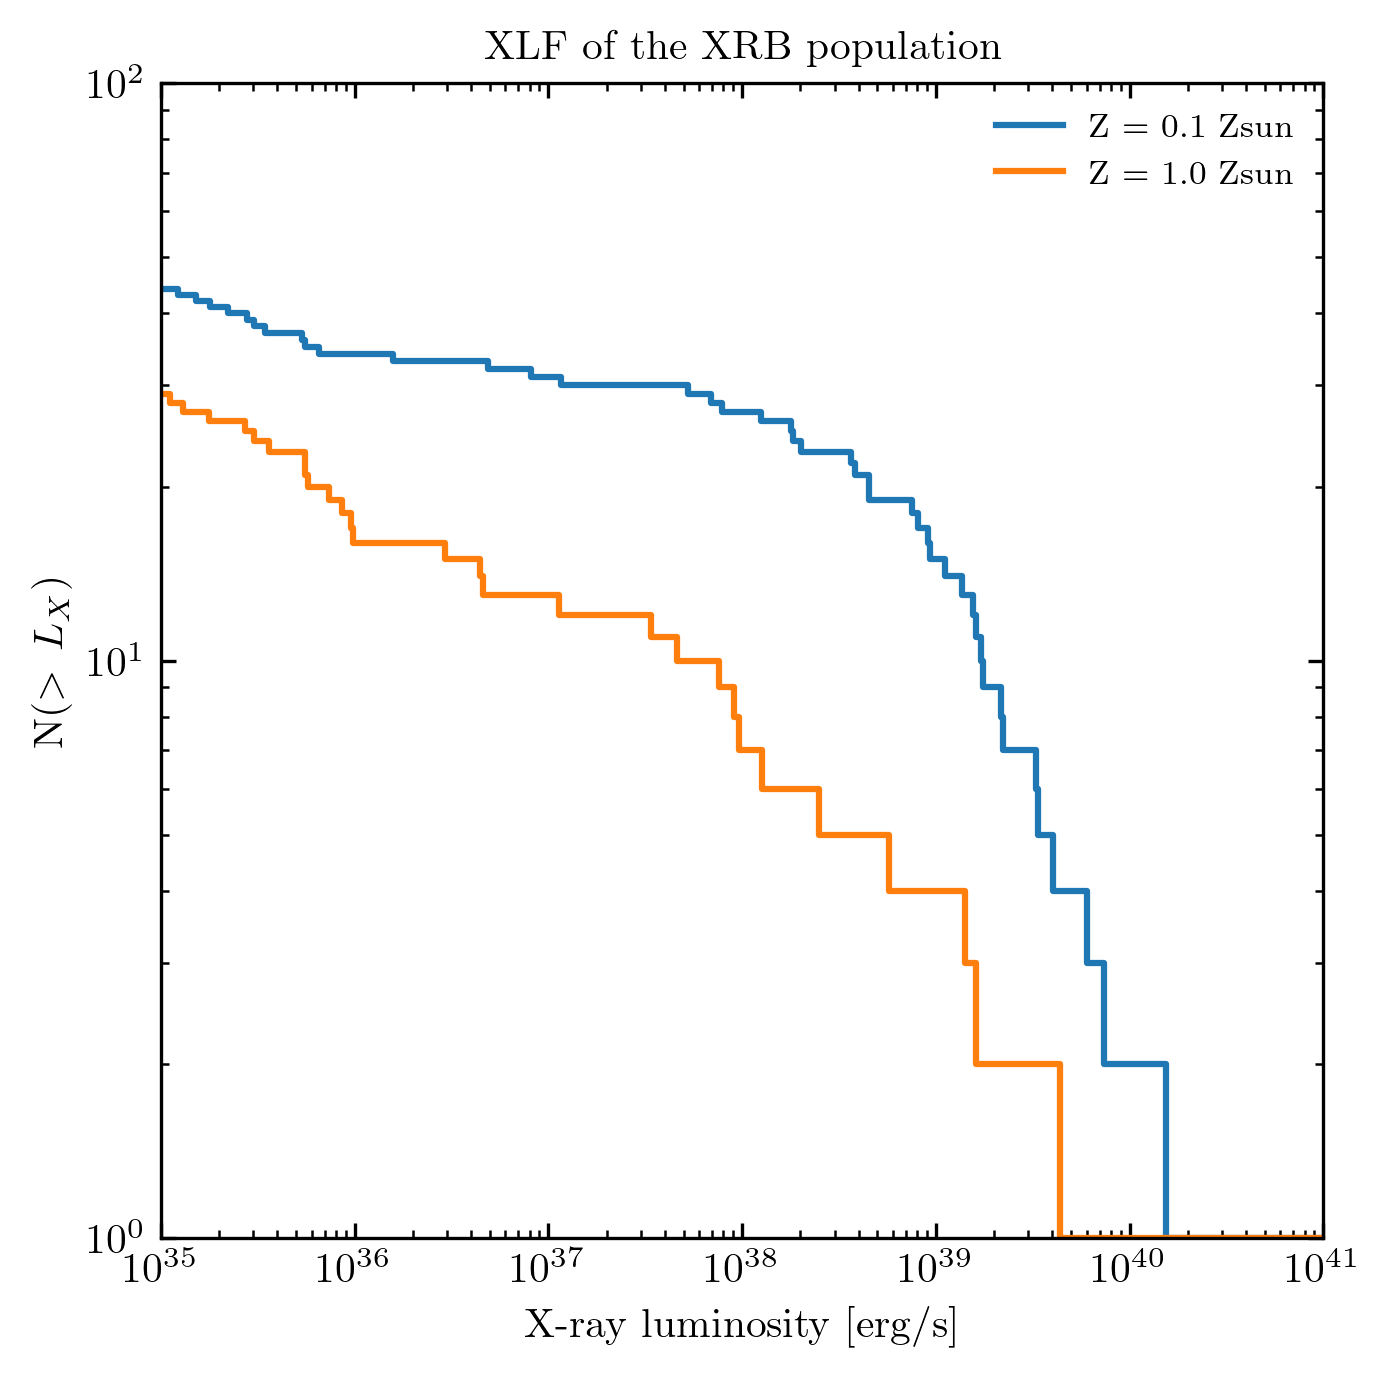

In [10]:
L01 = pd.to_numeric(XRB_pop01.population['Lx_Total']).to_numpy(dtype=float)
L1 = pd.to_numeric(XRB_pop1.population['Lx_Total']).to_numpy(dtype=float)

L_min = 1e30 # Given in erg/s

Mask01 = (L01 > L_min)
Mask1 = (L1 > L_min)

L01 = L01[Mask01]
L1 = L1[Mask1]

L01_sorted = np.sort(L01) # Sorted luminosities 
N_gt01 = np.cumsum(np.ones_like(L01_sorted, dtype=int))[::-1] # Number of XRBs having a luminosity greater than a given Lx

L1_sorted = np.sort(L1) # Sorted luminosities 
N_gt1 = np.cumsum(np.ones_like(L1_sorted, dtype=int))[::-1] # Number of XRBs having a luminosity greater than a given Lx

#----------------Plot----------------
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L01_sorted, N_gt01, label = 'Z = 0.1 Zsun')
axs.step(L1_sorted, N_gt1, label = 'Z = 1.0 Zsun')
axs.legend()
axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)')
axs.set_xlim(1e35, 1e41)
axs.set_ylim(1, 1e2)
plt.show()


In [11]:
pop_params01 = XRB_pop01.ini_params.copy()
pop_params01['primary_mass_min'] = 0.1
pop_params01['q_min'] = 0.0
pop_params01['q_max'] = 1.0

weights01 = XRB_pop01.calculate_model_weights(model_weights_identifier="base_IMF", population_parameters=pop_params01)

# These weights have unit of 1/Msun, and give the probability of each modeled system per unit of stellar mass formed in stars.
#display(weights01)

pop_params1 = XRB_pop1.ini_params.copy()
pop_params1['primary_mass_min'] = 0.1
pop_params1['q_min'] = 0.0
pop_params1['q_max'] = 1.0

weights1 = XRB_pop1.calculate_model_weights(model_weights_identifier="base_IMF", population_parameters=pop_params1)

# These weights have unit of 1/Msun, and give the probability of each modeled system per unit of stellar mass formed in stars.
#display(weights1)


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power


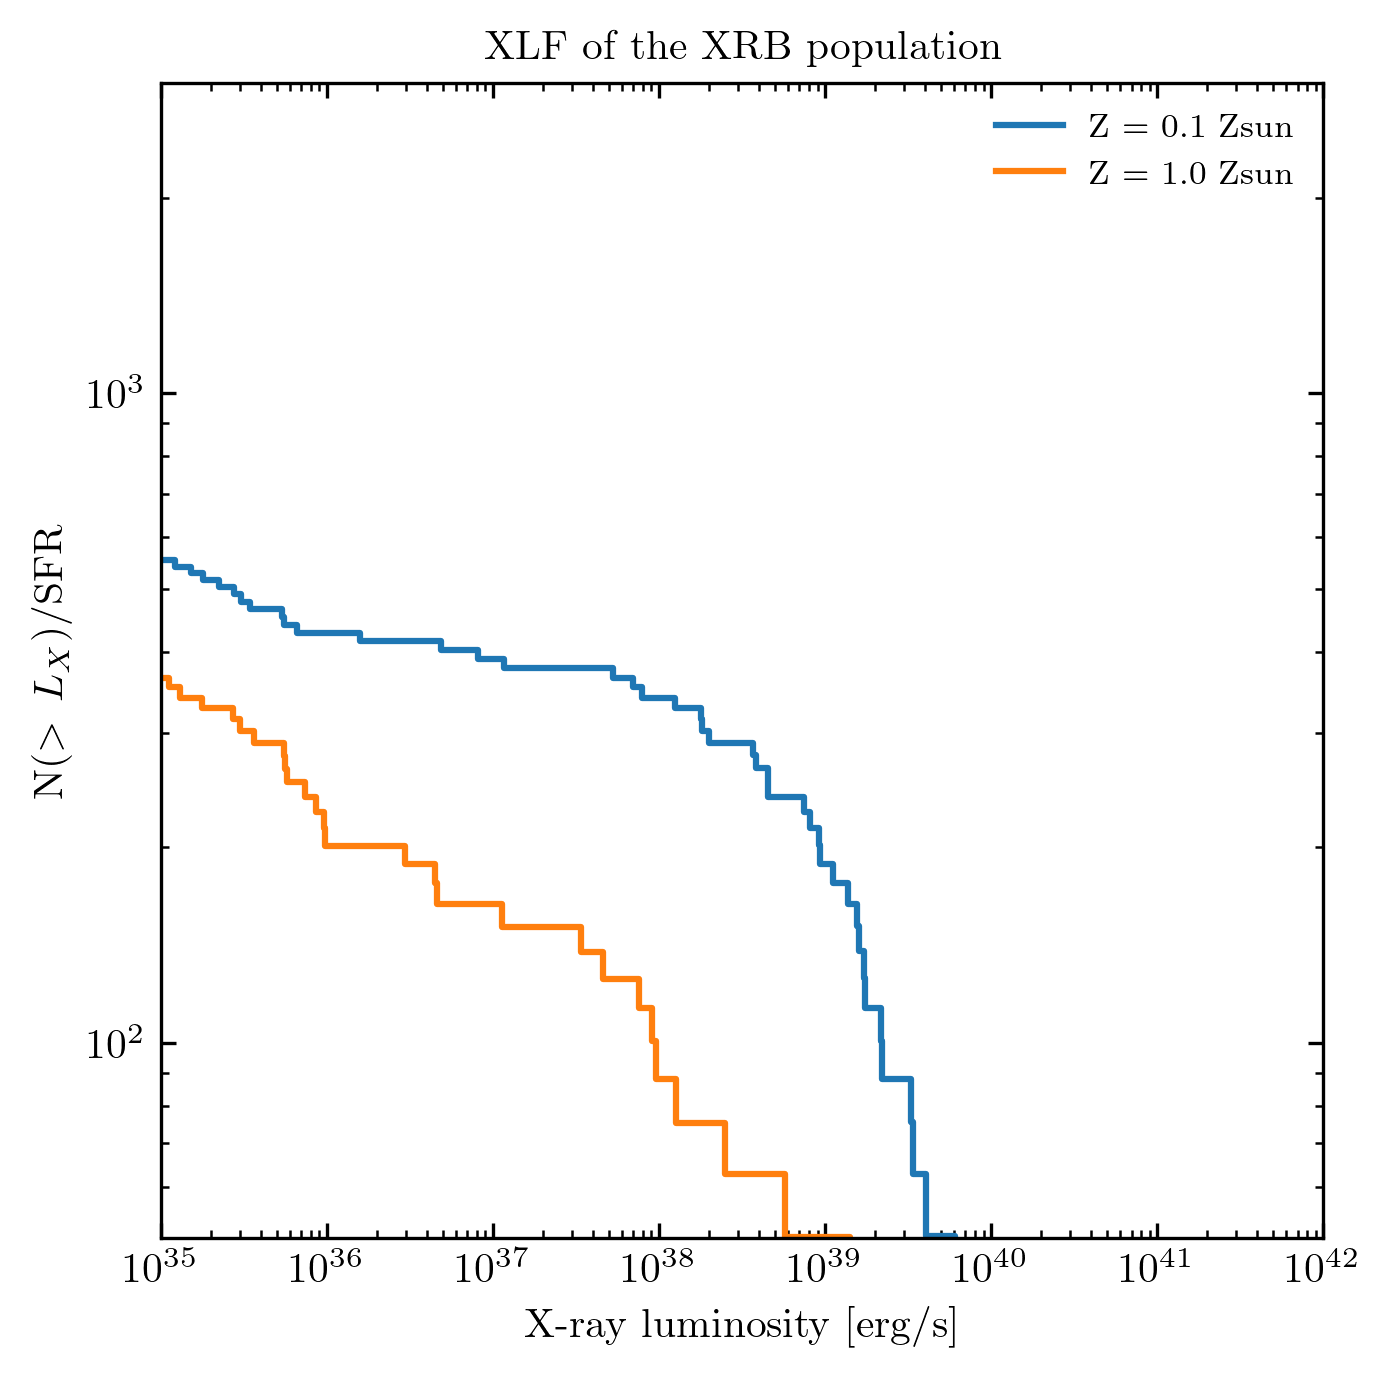

In [12]:
L01 = pd.to_numeric(XRB_pop01.population['Lx_Total']).to_numpy(dtype=float)
L1 = pd.to_numeric(XRB_pop1.population['Lx_Total']).to_numpy(dtype=float)

L_min = 1e30 # Given in erg/s
Total_underlying_mass = 1e8

Mask01 = (L01 > L_min)
Mask1 = (L1 > L_min)

L01 = L01[Mask01]
L1 = L1[Mask1]

weights01_masked = weights01.to_numpy(dtype = float)[Mask01]
weights1_masked = weights1.to_numpy(dtype = float)[Mask1]

L01_sorted = np.sort(L01) # Sorted luminosities 
weights01_sorted = weights01_masked[np.argsort(L01_sorted)]
N_gt01 = np.cumsum(weights01_sorted)[::-1] * Total_underlying_mass

L1_sorted = np.sort(L1) # Sorted luminosities 
N_gt1 = np.cumsum(weights1_masked[np.argsort(L1_sorted)])[::-1] * Total_underlying_mass

#----------------Plot----------------
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L01_sorted, N_gt01, label = 'Z = 0.1 Zsun')
axs.step(L1_sorted, N_gt1, label = 'Z = 1.0 Zsun')
axs.legend()
axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)/SFR')
axs.set_xlim(1e35, 1e42)
axs.set_ylim(50, 3e3)
plt.show()

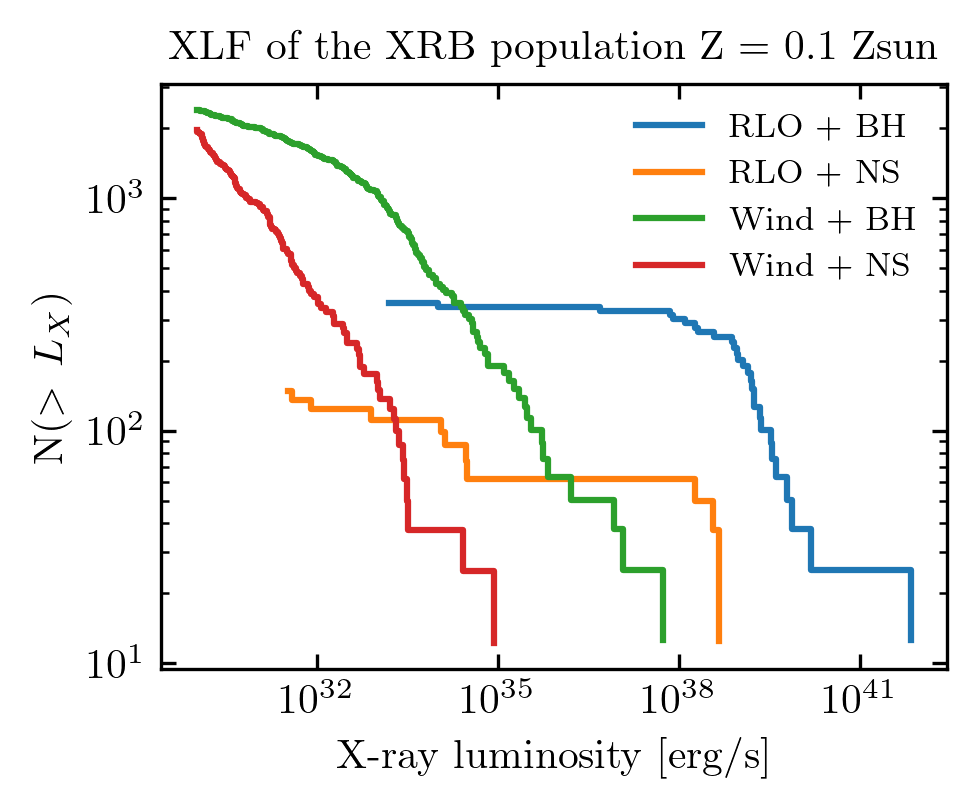

In [13]:
BH = XRB_pop01.population['Accretor_state'] == 'BH' # True/False pandas series
NS = XRB_pop01.population['Accretor_state'] == 'NS' # True/False pandas series
RLO = (XRB_pop01.population['Lx_RLO'] > XRB_pop01.population['Lx_BHL']) & (XRB_pop01.population['Lx_RLO'] > L_min) # True/False pandas series
Wind = (XRB_pop01.population['Lx_BHL'] > XRB_pop01.population['Lx_RLO']) & (XRB_pop01.population['Lx_BHL'] > L_min) # True/False pandas series

def plot_ccdf(vals, weight, label):
    x = np.sort(vals)                    # ascending
    y = np.cumsum(weight[np.argsort(vals)])[::-1]   # N(>x)
    plt.step(x, y, where='post', label=label)

plt.figure()
plot_ccdf(XRB_pop01.population.loc[RLO  & BH, 'Lx_Total'].to_numpy(), weights01[RLO  & BH].to_numpy() * Total_underlying_mass, 'RLO + BH')
plot_ccdf(XRB_pop01.population.loc[RLO  & NS, 'Lx_Total'].to_numpy(), weights01[RLO  & NS].to_numpy() * Total_underlying_mass, 'RLO + NS')
plot_ccdf(XRB_pop01.population.loc[Wind & BH, 'Lx_Total'].to_numpy(), weights01[Wind & BH].to_numpy() * Total_underlying_mass, 'Wind + BH')
plot_ccdf(XRB_pop01.population.loc[Wind & NS, 'Lx_Total'].to_numpy(), weights01[Wind & NS].to_numpy() * Total_underlying_mass, 'Wind + NS')

plt.title('XLF of the XRB population Z = 0.1 Zsun')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('X-ray luminosity [erg/s]')
plt.ylabel('N($>\, L_{X}$)')
plt.legend()
plt.show()

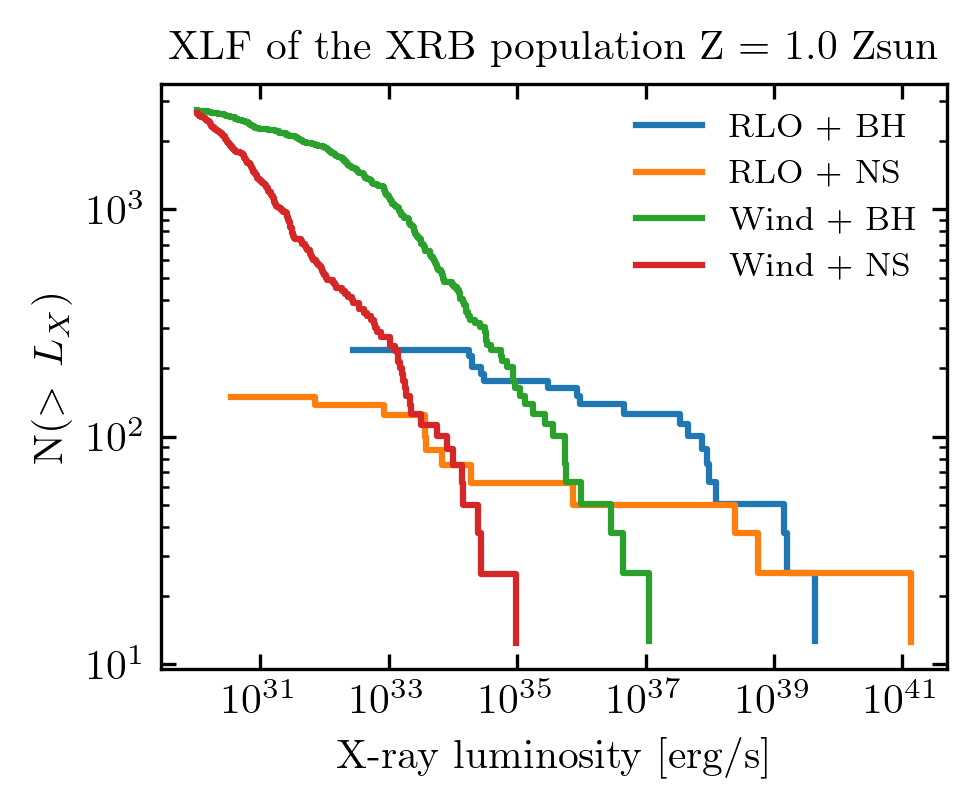

In [14]:
BH = XRB_pop1.population['Accretor_state'] == 'BH' # True/False pandas series
NS = XRB_pop1.population['Accretor_state'] == 'NS' # True/False pandas series
RLO = (XRB_pop1.population['Lx_RLO'] > XRB_pop1.population['Lx_BHL']) & (XRB_pop1.population['Lx_RLO'] > L_min) # True/False pandas series
Wind = (XRB_pop1.population['Lx_BHL'] > XRB_pop1.population['Lx_RLO']) & (XRB_pop1.population['Lx_BHL'] > L_min) # True/False pandas series

def plot_ccdf(vals, weight, label):
    x = np.sort(vals)                    # ascending
    y = np.cumsum(weight[np.argsort(vals)])[::-1]   # N(>x)
    plt.step(x, y, where='post', label=label)

plt.figure()
plot_ccdf(XRB_pop1.population.loc[RLO  & BH, 'Lx_Total'].to_numpy(), weights1[RLO  & BH].to_numpy() * Total_underlying_mass, 'RLO + BH')
plot_ccdf(XRB_pop1.population.loc[RLO  & NS, 'Lx_Total'].to_numpy(), weights1[RLO  & NS].to_numpy() * Total_underlying_mass, 'RLO + NS')
plot_ccdf(XRB_pop1.population.loc[Wind & BH, 'Lx_Total'].to_numpy(), weights1[Wind & BH].to_numpy() * Total_underlying_mass, 'Wind + BH')
plot_ccdf(XRB_pop1.population.loc[Wind & NS, 'Lx_Total'].to_numpy(), weights1[Wind & NS].to_numpy() * Total_underlying_mass, 'Wind + NS')

plt.title('XLF of the XRB population Z = 1.0 Zsun')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('X-ray luminosity [erg/s]')
plt.ylabel('N($>\, L_{X}$)')
plt.legend()
plt.show()